# Result analysis: 7 planners on Gambler and FrozenLake (model mismatch)

**Data:** `experiments/results/<algo>/<env>/sims<N>[/eps<e>]/summary.csv`, one row per pair (θ_plan, θ_exec), produced by `run.py`.

- Gambler: θ = p_h, θ_plan ∈ {0.4, 0.6, 0.8}, θ_exec ∈ {0.2, …, 0.8} → 21 pairs.
- FrozenLake 8x8: θ = slip_rate, θ_plan ∈ {0.1, …, 0.4}, θ_exec ∈ {0.0, …, 0.8} → 36 pairs.
- Each pair: 100 seeds × 2 episodes. Config = the rank-1 config of `tune.py` for that (algo, env, sims[, eps]).

**Main metric:** `mean_regret_true` = mean per-step regret V*(θ_exec)(s) − Q*(θ_exec)(s, a), where Q* comes from value iteration on the real model (ground truth). Smaller is better. A row's regret is the mean over all (θ_plan, θ_exec) pairs; SE = √(Σ se²)/n_pairs.

**Read the numbers with these caveats:**
1. `tune.py` selects configs on the same θ_exec grid used here, and "best ε" below is again chosen on these results → the numbers are optimistic for every method in the same way. They are fine for comparing methods, not as held-out performance.
2. `time_per_search` was measured while other jobs shared the CPU and robust-uct was sped up on 03/11 (same results, faster code). Times are indicative only.
3. ε values differ per method: GS Robust {0.05, …, 0.5}, GSF Robust {0.005, 0.1, …, 0.5}, Robust Power UCT {0.1, …, 0.5} + one run with ε tuned jointly ("tuned"). Common values: 0.1, 0.2, 0.3, 0.5.

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200, "display.max_columns", 30)
ROOT = "results"
ENVS = ["gambler", "frozen_lake"]
SIMS = [100, 300, 500, 700, 1000]

# name, search structure, robust?
ALGOS = {
    "uct":             ("UCT",              "UCT",        False),
    "st_power_uct":    ("Stoch. Power UCT", "tree",       False),
    "gs_power_uct":    ("GS Power UCT",     "depth merge", False),
    "gs_power_uct_f":  ("GSF Power UCT",    "full merge", False),
    "robust_uct":      ("Robust Power UCT", "tree",       True),
    "gs_robust_uct":   ("GS Robust UCT",    "depth merge", True),
    "gs_robust_uct_f": ("GSF Robust UCT",   "full merge", True),
}
ORDER = [v[0] for v in ALGOS.values()]
# color = search structure (fixed categorical order), line = robust (solid) / non-robust (dashed)
COLOR = {"UCT": "#2a78d6", "tree": "#eb6834", "depth merge": "#1baf7a", "full merge": "#eda100"}
MARK = {"UCT": "o", "tree": "s", "depth merge": "^", "full merge": "D"}
STYLE = {name: dict(color=COLOR[s], marker=MARK[s], linestyle="-" if r else "--", lw=2, ms=7,
                    markerfacecolor=COLOR[s] if r else "white", markeredgewidth=1.5)
         for name, s, r in ALGOS.values()}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10, "figure.dpi": 110})


def load() -> pd.DataFrame:
    parts = []
    for f in glob.glob(f"{ROOT}/*/*/sims*/**/summary.csv", recursive=True):
        rel = os.path.relpath(f, ROOT).split(os.sep)
        algo, env, sims = rel[0], rel[1], int(rel[2][4:])
        if algo not in ALGOS:
            continue
        d = pd.read_csv(f)
        d["algo"], d["env"], d["sims"] = algo, env, sims
        d["eps"] = rel[3][3:] if len(rel) == 5 else ("tuned" if ALGOS[algo][2] else "-")
        parts.append(d)
    df = pd.concat(parts, ignore_index=True)
    df["name"] = df.algo.map(lambda a: ALGOS[a][0])
    df["structure"] = df.algo.map(lambda a: ALGOS[a][1])
    df["robust"] = df.algo.map(lambda a: ALGOS[a][2])
    return df


def aggregate(df: pd.DataFrame) -> pd.DataFrame:
    g = df.groupby(["env", "name", "structure", "robust", "sims", "eps"])
    out = g.agg(regret=("mean_regret_true", "mean"), worst_regret=("mean_regret_true", "max"),
                success=("success_rate", "mean"), disc_reward=("mean_disc_reward", "mean"),
                time=("time_per_search", "median"), n_pairs=("mean_regret_true", "size"),
                c=("exploration_const", "first"), p=("p", "first")).reset_index()
    out["regret_se"] = g["regret_true_se"].apply(lambda s: np.sqrt((s ** 2).sum()) / len(s)).values
    return out


df = load()
A = aggregate(df)
best = A.loc[A.groupby(["env", "name", "sims"]).regret.idxmin()]   # best eps per (env, method, sims)
print(f"{len(df)} (pair) rows, {len(A)} (env, method, sims, eps) runs")

5307 (pair) rows, 187 (env, method, sims, eps) runs


### Completeness check: which runs exist (number of ε values per cell)

In [2]:
done = A[A.n_pairs == A.groupby("env").n_pairs.transform("max")]
tab = done.groupby(["env", "name", "sims"]).eps.apply(lambda e: ", ".join(sorted(e))).unstack("sims")
tab.reindex(pd.MultiIndex.from_product([ENVS, ORDER]))

sims                                               100                        300                        500                        700                        1000
gambler     UCT                                       -                          -                          -                          -                          -
            Stoch. Power UCT                          -                          -                          -                          -                          -
            GS Power UCT                              -                          -                          -                          -                          -
            GSF Power UCT                             -                          -                          -                          -                          -
            Robust Power UCT  0.1, 0.2, 0.3, 0.5, tuned  0.1, 0.2, 0.3, 0.5, tuned  0.1, 0.2, 0.3, 0.5, tuned  0.1, 0.2, 0.3, 0.5, tuned  0.1, 0.2, 0.3, 0.5, tuned
            GS Robust UCT      0.05, 0.1, 0.2, 0.3, 0.5   0.05, 0.1, 0.2, 0.3, 0.5   0.05, 0.1, 0.2, 0.3, 0.5   0.05, 0.1, 0.2, 0.3, 0.5   0.05, 0.1, 0.2, 0.3, 0.5
            GSF Robust UCT    0.005, 0.1, 0.2, 0.3, 0.5  0.005, 0.1, 0.2, 0.3, 0.5  0.005, 0.1, 0.2, 0.3, 0.5  0.005, 0.1, 0.2, 0.3, 0.5  0.005, 0.1, 0.2, 0.3, 0.5
frozen_lake UCT                                       -                          -                          -                          -                          -
            Stoch. Power UCT                          -                          -                          -                          -                          -
            GS Power UCT                              -                          -                          -                          -                          -
            GSF Power UCT                             -                          -                          -                          -                          -
            Robust Power UCT  0.1, 0.2, 0.3, 0.5, tuned  0.1, 0.2, 0.3, 0.5, tuned  0.1, 0.2, 0.3, 0.5, tuned  0.1, 0.2, 0.3, 0.5, tuned  0.1, 0.2, 0.3, 0.5, tuned
            GS Robust UCT      0.05, 0.1, 0.2, 0.3, 0.5   0.05, 0.1, 0.2, 0.3, 0.5   0.05, 0.1, 0.2, 0.3, 0.5   0.05, 0.1, 0.2, 0.3, 0.5   0.05, 0.1, 0.2, 0.3, 0.5
            GSF Robust UCT    0.005, 0.1, 0.2, 0.3, 0.5  0.005, 0.1, 0.2, 0.3, 0.5  0.005, 0.1, 0.2, 0.3, 0.5  0.005, 0.1, 0.2, 0.3, 0.5                   0.1, 0.2

---
# Main Comparison

Each robust method is shown with its best ε at each budget (lowest mean regret; ε in brackets). Non-robust methods have no ε.

In [3]:
def fmt(r):
    tag = f" [{r.eps}]" if r.eps != "-" else ""
    return f"{r.regret:.4f} ± {r.regret_se:.4f}{tag}"

for env in ENVS:
    t = best[best.env == env].assign(v=lambda x: x.apply(fmt, axis=1)).pivot(index="name", columns="sims", values="v")
    print(f"\n=== {env}: mean regret_true ± SE [best eps]")
    display(t.reindex(ORDER))


=== gambler: mean regret_true ± SE [best eps]


sims,100,300,500,700,1000
name,,,,,
UCT,0.0307 ± 0.0006,0.0301 ± 0.0005,0.0292 ± 0.0005,0.0336 ± 0.0004,0.0344 ± 0.0003
Stoch. Power UCT,0.0194 ± 0.0004,0.0154 ± 0.0001,0.0149 ± 0.0001,0.0150 ± 0.0001,0.0147 ± 0.0001
GS Power UCT,0.0175 ± 0.0002,0.0150 ± 0.0001,0.0137 ± 0.0001,0.0134 ± 0.0001,0.0132 ± 0.0001
GSF Power UCT,0.0160 ± 0.0002,0.0148 ± 0.0003,0.0136 ± 0.0002,0.0134 ± 0.0002,0.0132 ± 0.0002
Robust Power UCT,0.0179 ± 0.0003 [0.2],0.0150 ± 0.0002 [0.1],0.0141 ± 0.0002 [0.1],0.0131 ± 0.0001 [0.1],0.0132 ± 0.0001 [0.1]
GS Robust UCT,0.0142 ± 0.0001 [0.05],0.0121 ± 0.0001 [0.05],0.0120 ± 0.0001 [0.05],0.0120 ± 0.0001 [0.05],0.0122 ± 0.0001 [0.05]
GSF Robust UCT,0.0161 ± 0.0003 [0.005],0.0214 ± 0.0005 [0.005],0.0255 ± 0.0005 [0.005],0.0273 ± 0.0005 [0.005],0.0292 ± 0.0004 [0.005]



=== frozen_lake: mean regret_true ± SE [best eps]


sims,100,300,500,700,1000
name,,,,,
UCT,0.0287 ± 0.0002,0.0257 ± 0.0002,0.0239 ± 0.0002,0.0230 ± 0.0002,0.0210 ± 0.0002
Stoch. Power UCT,0.0280 ± 0.0002,0.0250 ± 0.0002,0.0228 ± 0.0002,0.0211 ± 0.0002,0.0193 ± 0.0002
GS Power UCT,0.0275 ± 0.0002,0.0232 ± 0.0002,0.0207 ± 0.0002,0.0185 ± 0.0002,0.0170 ± 0.0002
GSF Power UCT,0.0161 ± 0.0001,0.0156 ± 0.0001,0.0149 ± 0.0001,0.0147 ± 0.0001,0.0149 ± 0.0001
Robust Power UCT,0.0294 ± 0.0002 [tuned],0.0272 ± 0.0002 [0.2],0.0252 ± 0.0002 [tuned],0.0245 ± 0.0002 [0.1],0.0223 ± 0.0002 [tuned]
GS Robust UCT,0.0279 ± 0.0002 [0.05],0.0213 ± 0.0002 [0.1],0.0171 ± 0.0002 [0.2],0.0145 ± 0.0002 [0.2],0.0111 ± 0.0001 [0.2]
GSF Robust UCT,0.0152 ± 0.0001 [0.3],0.0120 ± 0.0001 [0.3],0.0107 ± 0.0001 [0.3],0.0101 ± 0.0001 [0.3],0.0087 ± 0.0001 [0.2]


### Scenario summary: matched / harder / easier, one fixed ε per method

**ε is fixed per (env, method)**, not re-chosen per N:
- Candidates: the ε values that have results at every N (and "tuned" for Robust Power UCT).
- Keep the candidates whose success rate, averaged over N, is not lower than the non-robust method with the same structure. This guards against "stalling" configs.
- Among those, take the lowest regret averaged over N.

**Scenarios**, with Δ = θ_exec − θ_plan:
- **matched**: Δ = 0.
- **harder**: the real environment is harder than the model (FrozenLake: more slippery, Δ > 0; Gambler: smaller p_h, Δ < 0).
- **easier**: the opposite.
- **worst case**: the max regret over all pairs.

Cells = **success rate** (= mean reward; reward is 1 only at the goal) at N = 100 and N = 1000; worst case = lowest success over all pairs; 'all pairs' = mean over every pair. Bold marks the best value in each column.
Output files: `report_figures/table_scenarios.{md,tex,csv}` (success) and `report_figures/table_scenarios_regret.*` (regret).

In [4]:
HARDER = {"frozen_lake": lambda d: d > 0, "gambler": lambda d: d < 0}
PARTNER = {"Robust Power UCT": "Stoch. Power UCT", "GS Robust UCT": "GS Power UCT", "GSF Robust UCT": "GSF Power UCT"}

def fixed_eps(env):
    out = {}
    a = A[A.env == env]
    for name in ORDER:
        x = a[a.name == name]
        full = x.groupby("eps").filter(lambda g: set(SIMS) <= set(g.sims))
        stats = full.groupby("eps").agg(regret=("regret", "mean"), success=("success", "mean"))
        if name in PARTNER:
            ref = a[a.name == PARTNER[name]].success.mean()
            ok = stats[stats.success >= ref]
            stats = ok if len(ok) else stats
        out[name] = stats.regret.idxmin()
    return out

FIXED = {env: fixed_eps(env) for env in ENVS}
for env in ENVS:
    print(env, FIXED[env])

METRIC = {"success": ("success_rate", "success rate", True), "regret": ("mean_regret_true", "regret", False)}

def scenario_table(env, metric="success", Ns=(100, 1000)):
    col, label, higher = METRIC[metric]
    d = df[(df.env == env) & df.sims.isin(Ns)].copy()
    d = d[d.apply(lambda r: r.eps == FIXED[env][r["name"]], axis=1)]
    d["delta"] = (d.theta_exec - d.theta_plan).round(2)
    d["scenario"] = np.where(d.delta == 0, "matched Δ=0", np.where(HARDER[env](d.delta), "harder", "easier"))
    cols = {}
    for sc in ["matched Δ=0", "harder", "easier"]:
        n = d[(d.scenario == sc) & (d.sims == Ns[0]) & (d.name == "UCT")].shape[0]
        g = d[d.scenario == sc].groupby(["name", "sims"])[col].mean().unstack("sims")
        for N in Ns:
            cols[(f"{label}: {sc} (n={n})", f"N={N}")] = g[N]
    w = d.groupby(["name", "sims"])[col]
    w = (w.min() if higher else w.max()).unstack("sims")
    for N in Ns:
        cols[(f"{label}: worst case ({'min' if higher else 'max'} over pairs)", f"N={N}")] = w[N]
    a = d.groupby(["name", "sims"])[col].mean().unstack("sims")
    for N in Ns:
        cols[(f"{label}: all pairs", f"N={N}")] = a[N]
    t = pd.DataFrame(cols).reindex(ORDER)
    t.index = [n if FIXED[env][n] == "-" else f"{n} (ε={FIXED[env][n]})" for n in t.index]
    return t, higher

def render(t, higher):
    md_rows, tex_rows = [], []
    best_col = {c: (t[c].max() if higher else t[c].min()) for c in t.columns}
    fmt = "{:.3f}" if higher else "{:.4f}"
    for name, r in t.iterrows():
        cm, ct = [], []
        for c in t.columns:
            f = fmt.format(r[c]); top = r[c] == best_col[c]
            cm.append(f"**{f}**" if top else f); ct.append(r"\textbf{%s}" % f if top else f)
        md_rows.append(f"| {name} | " + " | ".join(cm) + " |")
        tex_rows.append(name.replace("ε", r"$\varepsilon$") + " & " + " & ".join(ct) + r" \\")
        if name.startswith("GSF Power"):
            tex_rows.append(r"\midrule")
    groups = list(dict.fromkeys(c[0] for c in t.columns))
    h1 = "| Method | " + " | ".join(g + " |" * (sum(c[0] == g for c in t.columns) - 1) for g in groups) + " |"
    h2 = "| | " + " | ".join(c[1] for c in t.columns) + " |"
    md = "\n".join([h1, "|---" * (len(t.columns) + 1) + "|", h2] + md_rows)
    tex = ("\\begin{tabular}{l" + "r" * len(t.columns) + "}\n\\toprule\n & "
           + " & ".join(r"\multicolumn{%d}{c}{%s}" % (sum(c[0] == g for c in t.columns), g.split(": ", 1)[1]) for g in groups) + r" \\" + "\n"
           + "Method & " + " & ".join(c[1] for c in t.columns) + r" \\" + "\n\\midrule\n" + "\n".join(tex_rows)
           + "\n\\bottomrule\n\\end{tabular}\n")
    return md, tex

TITLE = {"gambler": "Gambler", "frozen_lake": "FrozenLake 8x8"}
for metric, fname in [("success", "table_scenarios"), ("regret", "table_scenarios_regret")]:
    md_all, tex_all, csv_all = [], [], []
    for env in ENVS:
        t, higher = scenario_table(env, metric)
        m, x = render(t, higher)
        note = ("harder = smaller p_h than the model (Δ<0)" if env == "gambler" else "harder = more slippery than the model (Δ>0)")
        what = ("success rate (= mean reward, reward 1 only at the goal); higher is better; worst case = lowest success over all (θ_plan, θ_exec) pairs"
                if higher else "mean regret_true; lower is better; worst case = highest regret over all pairs")
        md_all.append(f"**{TITLE[env]}**: {what}; {note}; n = number of (θ_plan, θ_exec) pairs, each pair = 100 seeds × 2 episodes\n\n" + m)
        tex_all.append(f"% {TITLE[env]}: {what}\n" + x)
        csv_all.append(t.assign(env=env))
        print(f"\n=== {TITLE[env]}: {what}  ({note})")
        display(t.round(4))
    open(f"report_figures/{fname}.md", "w").write("\n\n".join(md_all) + "\n")
    open(f"report_figures/{fname}.tex", "w").write("\n".join(tex_all))
    pd.concat(csv_all).to_csv(f"report_figures/{fname}.csv")

gambler {'UCT': '-', 'Stoch. Power UCT': '-', 'GS Power UCT': '-', 'GSF Power UCT': '-', 'Robust Power UCT': '0.1', 'GS Robust UCT': '0.05', 'GSF Robust UCT': '0.005'}
frozen_lake {'UCT': '-', 'Stoch. Power UCT': '-', 'GS Power UCT': '-', 'GSF Power UCT': '-', 'Robust Power UCT': 'tuned', 'GS Robust UCT': '0.2', 'GSF Robust UCT': '0.2'}

=== Gambler: success rate (= mean reward, reward 1 only at the goal); higher is better; worst case = lowest success over all (θ_plan, θ_exec) pairs  (harder = smaller p_h than the model (Δ<0))


success rate: matched Δ=0 (n=3)         success rate: harder (n=12)         success rate: easier (n=6)         success rate: worst case (min over pairs)         \
                                                   N=100  N=1000                       N=100  N=1000                      N=100  N=1000                                     N=100 N=1000   
UCT                                               0.6833  0.7033                      0.3487  0.3375                     0.7850  0.7608                                     0.045  0.040   
Stoch. Power UCT                                  0.6833  0.6900                      0.3279  0.2979                     0.8267  0.8675                                     0.020  0.015   
GS Power UCT                                      0.6667  0.6733                      0.3196  0.3017                     0.8308  0.8642                                     0.025  0.010   
GSF Power UCT                                     0.6767  0.6783                      0.2996  0.2938                     0.8633  0.8658                                     0.010  0.010   
Robust Power UCT (ε=0.1)                          0.7000  0.6917                      0.3042  0.2825                     0.8283  0.8683                                     0.000  0.005   
GS Robust UCT (ε=0.05)                            0.7050  0.6867                      0.2950  0.2900                     0.8667  0.8767                                     0.010  0.005   
GSF Robust UCT (ε=0.005)                          0.6883  0.7450                      0.3104  0.3283                     0.8608  0.7842                                     0.015  0.005   

                         success rate: all pairs          
                                           N=100  N=1000  
UCT                                       0.5212  0.5107  
Stoch. Power UCT                          0.5212  0.5167  
GS Power UCT                              0.5152  0.5155  
GSF Power UCT                             0.5145  0.5121  
Robust Power UCT (ε=0.1)                  0.5105  0.5083  
GS Robust UCT (ε=0.05)                    0.5169  0.5143  
GSF Robust UCT (ε=0.005)                  0.5217  0.5181


=== FrozenLake 8x8: success rate (= mean reward, reward 1 only at the goal); higher is better; worst case = lowest success over all (θ_plan, θ_exec) pairs  (harder = more slippery than the model (Δ>0))


success rate: matched Δ=0 (n=4)         success rate: harder (n=22)         success rate: easier (n=10)         success rate: worst case (min over pairs)         \
                                                     N=100  N=1000                       N=100  N=1000                       N=100  N=1000                                     N=100 N=1000   
UCT                                                 0.0788  0.3200                      0.0214  0.0941                      0.0900  0.4635                                     0.000  0.000   
Stoch. Power UCT                                    0.0850  0.3575                      0.0223  0.0980                      0.1160  0.5215                                     0.000  0.000   
GS Power UCT                                        0.1100  0.5150                      0.0305  0.1386                      0.1945  0.7265                                     0.000  0.005   
GSF Power UCT                                       0.2700  0.4950                      0.0882  0.1532                      0.4030  0.7665                                     0.005  0.000   
Robust Power UCT (ε=tuned)                          0.0562  0.2838                      0.0198  0.0734                      0.0770  0.4040                                     0.000  0.000   
GS Robust UCT (ε=0.2)                               0.0912  0.6712                      0.0234  0.2534                      0.1375  0.8630                                     0.000  0.015   
GSF Robust UCT (ε=0.2)                              0.3100  0.7088                      0.0930  0.2545                      0.4610  0.8845                                     0.005  0.000   

                           success rate: all pairs          
                                             N=100  N=1000  
UCT                                         0.0468  0.2218  
Stoch. Power UCT                            0.0553  0.2444  
GS Power UCT                                0.0849  0.3438  
GSF Power UCT                               0.1958  0.3615  
Robust Power UCT (ε=tuned)                  0.0397  0.1886  
GS Robust UCT (ε=0.2)                       0.0626  0.4692  
GSF Robust UCT (ε=0.2)                      0.2193  0.4800


=== Gambler: mean regret_true; lower is better; worst case = highest regret over all pairs  (harder = smaller p_h than the model (Δ<0))


regret: matched Δ=0 (n=3)         regret: harder (n=12)         regret: easier (n=6)         regret: worst case (max over pairs)         regret: all pairs        
                                             N=100  N=1000                 N=100  N=1000                N=100  N=1000                               N=100  N=1000             N=100  N=1000
UCT                                         0.0170  0.0064                0.0238  0.0191               0.0513  0.0790                              0.1019  0.1807            0.0307  0.0344
Stoch. Power UCT                            0.0120  0.0094                0.0234  0.0211               0.0153  0.0045                              0.0364  0.0360            0.0194  0.0147
GS Power UCT                                0.0106  0.0076                0.0225  0.0193               0.0110  0.0038                              0.0356  0.0320            0.0175  0.0132
GSF Power UCT                               0.0092  0.0067                0.0207  0.0183               0.0101  0.0062                              0.0338  0.0300            0.0160  0.0132
Robust Power UCT (ε=0.1)                    0.0110  0.0087                0.0213  0.0185               0.0159  0.0049                              0.0354  0.0344            0.0183  0.0132
GS Robust UCT (ε=0.05)                      0.0094  0.0071                0.0202  0.0174               0.0047  0.0044                              0.0353  0.0296            0.0142  0.0122
GSF Robust UCT (ε=0.005)                    0.0085  0.0024                0.0199  0.0153               0.0123  0.0705                              0.0320  0.1650            0.0161  0.0292


=== FrozenLake 8x8: mean regret_true; lower is better; worst case = highest regret over all pairs  (harder = more slippery than the model (Δ>0))


regret: matched Δ=0 (n=4)         regret: harder (n=22)         regret: easier (n=10)         regret: worst case (max over pairs)         regret: all pairs        
                                               N=100  N=1000                 N=100  N=1000                 N=100  N=1000                               N=100  N=1000             N=100  N=1000
UCT                                           0.0320  0.0214                0.0222  0.0189                0.0417  0.0252                              0.0496  0.0344            0.0287  0.0210
Stoch. Power UCT                              0.0318  0.0197                0.0217  0.0186                0.0405  0.0205                              0.0475  0.0254            0.0280  0.0193
GS Power UCT                                  0.0315  0.0155                0.0222  0.0185                0.0377  0.0140                              0.0475  0.0222            0.0275  0.0170
GSF Power UCT                                 0.0167  0.0134                0.0155  0.0170                0.0173  0.0107                              0.0199  0.0195            0.0161  0.0149
Robust Power UCT (ε=tuned)                    0.0338  0.0238                0.0223  0.0198                0.0433  0.0274                              0.0532  0.0335            0.0294  0.0223
GS Robust UCT (ε=0.2)                         0.0324  0.0091                0.0219  0.0132                0.0397  0.0071                              0.0481  0.0159            0.0281  0.0111
GSF Robust UCT (ε=0.2)                        0.0150  0.0058                0.0149  0.0118                0.0162  0.0030                              0.0181  0.0143            0.0153  0.0087

### Main table (report): success rate by budget N (rows) and model mismatch Δ (columns)

- Δ = θ_exec − θ_plan: the gap between the real environment and the model the planner uses.
  - FrozenLake: Δ > 0 means the real lake is more slippery (harder).
  - Gambler: Δ < 0 means the real p_h is smaller than the model's (harder).
- Columns: one Δ per level, |Δ| = 0.3 / 0.2 / 0.1 on the easier side, Δ = 0, and |Δ| = 0.1 / 0.2 / 0.3 on the harder side (same |Δ| in both envs).
- Cell = success rate (= mean reward; reward 1 only at the goal), averaged over the (θ_plan, θ_exec) pairs in that level. n is the number of pairs; each pair = 100 seeds × 2 episodes.
- Rows: for each N ∈ {100, 300, 500, 700, 1000}, all 7 methods. ε is fixed per method (see above).
- Bold = best method for that N and mismatch level.
- Files: `report_figures/table_main.{md,tex,csv}` (success) and `report_figures/table_main_regret.*` (same layout, regret, lower is better).

In [5]:
# mismatch levels: |Δ| bins on the harder and on the easier side (sign of "harder" differs per env)
LEVELS = {   # one Δ per level, same |Δ| = 0.1 / 0.2 / 0.3 on both sides and in both envs
    "frozen_lake": [("easier", "large", [-0.3]), ("easier", "medium", [-0.2]), ("easier", "small", [-0.1]),
                    ("matched", "Δ=0", [0.0]),
                    ("harder", "small", [0.1]), ("harder", "medium", [0.2]), ("harder", "large", [0.3])],
    "gambler":     [("easier", "large", [0.3]), ("easier", "medium", [0.2]), ("easier", "small", [0.1]),
                    ("matched", "Δ=0", [0.0]),
                    ("harder", "small", [-0.1]), ("harder", "medium", [-0.2]), ("harder", "large", [-0.3])],
}

def level_label(side, lvl, ds):
    if side == "matched":
        return "Δ=0"
    lo, hi = min(ds), max(ds)
    rng = f"{lo:+.1f}" if lo == hi else f"{lo:+.1f}…{hi:+.1f}"
    return f"{lvl} (Δ {rng})"

def delta_table(env, metric="success"):
    col, label, higher = METRIC[metric]
    d = df[df.env == env].copy()
    d = d[d.apply(lambda r: r.eps == FIXED[env][r["name"]], axis=1)]
    d["delta"] = (d.theta_exec - d.theta_plan).round(2)
    keys = []
    for side, lvl, ds in LEVELS[env]:
        k = (side, level_label(side, lvl, ds)); keys.append(k)
        d.loc[d.delta.isin(ds), ["side", "level"]] = k
    t = d.pivot_table(index=["sims", "name"], columns=["side", "level"], values=col, aggfunc="mean")
    t = t.reindex(columns=pd.MultiIndex.from_tuples(keys))
    t = t.reindex(pd.MultiIndex.from_product([SIMS, ORDER], names=["N", "method"]))
    n = d[(d.sims == SIMS[0]) & (d.name == "UCT")].groupby(["side", "level"]).size()
    return t, n, higher

def render_delta(t, n, higher, env):
    fmt = "{:.3f}" if higher else "{:.4f}"
    keys = list(t.columns)
    sides = list(dict.fromkeys(k[0] for k in keys))
    span = {sd: sum(k[0] == sd for k in keys) for sd in sides}
    side_name = {"easier": "real env EASIER than the model", "matched": "no mismatch", "harder": "real env HARDER than the model"}
    def lab(name):
        e = FIXED[env][name]
        return name if e == "-" else f"{name} (ε={e})"
    md = ["| N | Method | " + " | ".join(f"{side_name[k[0]] if k == next(x for x in keys if x[0] == k[0]) else ''}" for k in keys) + " |",
          "|---" * (len(keys) + 2) + "|",
          "| | mismatch level | " + " | ".join(k[1] for k in keys) + " |",
          "| | n pairs | " + " | ".join(str(n[k]) for k in keys) + " |"]
    tex = ["\\begin{tabular}{ll" + "r" * len(keys) + "}", "\\toprule",
           " & & " + " & ".join(r"\multicolumn{%d}{c}{%s}" % (span[sd], side_name[sd]) for sd in sides) + r" \\",
           " & & " + " & ".join(k[1].replace("Δ", r"$\Delta$").replace("…", r"..") for k in keys) + r" \\",
           "$N$ & Method / \\emph{n pairs} & " + " & ".join(str(n[k]) for k in keys) + r" \\", "\\midrule"]
    for N in SIMS:
        blk = t.loc[N]
        bestv = blk.max() if higher else blk.min()
        for i, name in enumerate(ORDER):
            cm, ct = [], []
            for k in keys:
                v = blk.loc[name, k]
                f = fmt.format(v); top = v == bestv[k]
                cm.append(f"**{f}**" if top else f); ct.append(r"\textbf{%s}" % f if top else f)
            md.append(f"| {N if i == 0 else ''} | {lab(name)} | " + " | ".join(cm) + " |")
            tex.append(f"{N if i == 0 else ''} & {lab(name).replace('ε', '$\\varepsilon$')} & " + " & ".join(ct) + r" \\")
        tex.append("\\midrule" if N != SIMS[-1] else "\\bottomrule")
    tex.append("\\end{tabular}")
    return "\n".join(md), "\n".join(tex) + "\n"

for metric, fname in [("success", "table_main"), ("regret", "table_main_regret")]:
    md_all, tex_all, csv_all = [], [], []
    for env in ENVS:
        t, n, higher = delta_table(env, metric)
        m, x = render_delta(t, n, higher, env)
        harder = "Δ<0 = real p_h smaller than the model (harder)" if env == "gambler" else "Δ>0 = real lake more slippery than the model (harder)"
        what = "success rate (= mean reward), higher is better" if higher else "mean regret_true, lower is better"
        md_all.append(f"**{TITLE[env]}**: {what}; {harder}; bold = best method for each N and mismatch level\n\n" + m)
        tex_all.append(f"% {TITLE[env]}: {what}; {harder}\n" + x)
        csv_all.append(t.assign(env=env))
        if metric == "success":
            print(f"\n=== {TITLE[env]}: {what}  ({harder})")
            with pd.option_context("display.max_rows", 100):
                display(t.round(3))
    open(f"report_figures/{fname}.md", "w").write("\n\n".join(md_all) + "\n")
    open(f"report_figures/{fname}.tex", "w").write("\n".join(tex_all))
    pd.concat(csv_all).to_csv(f"report_figures/{fname}.csv")


=== Gambler: success rate (= mean reward), higher is better  (Δ<0 = real p_h smaller than the model (harder))


easier                                matched         harder                               
                      large (Δ +0.3) medium (Δ +0.2) small (Δ +0.1)     Δ=0 small (Δ -0.1) medium (Δ -0.2) large (Δ -0.3)
N    method                                                                                                              
100  UCT                       0.805           0.802          0.700   0.683          0.555           0.388          0.358
     Stoch. Power UCT          0.880           0.850          0.722   0.683          0.542           0.368          0.332
     GS Power UCT              0.875           0.842          0.732   0.667          0.523           0.360          0.332
     GSF Power UCT             0.910           0.872          0.770   0.677          0.518           0.332          0.285
     Robust Power UCT          0.855           0.850          0.748   0.700          0.548           0.362          0.298
     GS Robust UCT             0.945           0.883          0.755   0.705          0.538           0.337          0.293
     GSF Robust UCT            0.920           0.878          0.765   0.688          0.538           0.362          0.295
300  UCT                       0.810           0.810          0.708   0.687          0.562           0.387          0.318
     Stoch. Power UCT          0.925           0.872          0.718   0.688          0.528           0.363          0.310
     GS Power UCT              0.930           0.898          0.755   0.680          0.528           0.340          0.312
     GSF Power UCT             0.935           0.900          0.752   0.698          0.530           0.347          0.295
     Robust Power UCT          0.910           0.860          0.738   0.687          0.530           0.350          0.288
     GS Robust UCT             0.965           0.925          0.770   0.672          0.513           0.337          0.300
     GSF Robust UCT            0.810           0.840          0.758   0.728          0.567           0.367          0.310
500  UCT                       0.825           0.812          0.715   0.690          0.560           0.383          0.350
     Stoch. Power UCT          0.915           0.885          0.728   0.677          0.523           0.335          0.305
     GS Power UCT              0.960           0.910          0.755   0.670          0.515           0.342          0.305
     GSF Power UCT             0.945           0.908          0.765   0.697          0.518           0.337          0.310
     Robust Power UCT          0.895           0.880          0.745   0.705          0.532           0.357          0.283
     GS Robust UCT             0.960           0.918          0.772   0.677          0.513           0.337          0.272
     GSF Robust UCT            0.775           0.805          0.732   0.730          0.585           0.370          0.288
700  UCT                       0.745           0.782          0.698   0.707          0.578           0.405          0.330
     Stoch. Power UCT          0.910           0.875          0.738   0.668          0.507           0.333          0.322
     GS Power UCT              0.950           0.908          0.755   0.702          0.510           0.337          0.292
     GSF Power UCT             0.920           0.888          0.775   0.698          0.518           0.325          0.288
     Robust Power UCT          0.950           0.898          0.745   0.680          0.525           0.357          0.293
     GS Robust UCT             0.975           0.928          0.750   0.680          0.505           0.325          0.283
     GSF Robust UCT            0.765           0.812          0.722   0.740          0.580           0.388          0.312
1000 UCT                       0.735           0.782          0.710   0.703          0.580           0.392          0.312
     Stoch. Power UCT          0.935           0.888          0.755   0.690          0.505           0.322          0.298
    


=== FrozenLake 8x8: success rate (= mean reward), higher is better  (Δ>0 = real lake more slippery than the model (harder))


easier                                matched         harder                               
                      large (Δ -0.3) medium (Δ -0.2) small (Δ -0.1)     Δ=0 small (Δ +0.1) medium (Δ +0.2) large (Δ +0.3)
N    method                                                                                                              
100  UCT                       0.100           0.088          0.089   0.079          0.053           0.025          0.020
     Stoch. Power UCT          0.112           0.120          0.110   0.085          0.055           0.022          0.024
     GS Power UCT              0.255           0.187          0.162   0.110          0.068           0.039          0.029
     GSF Power UCT             0.445           0.403          0.362   0.270          0.212           0.143          0.071
     Robust Power UCT          0.080           0.073          0.069   0.056          0.049           0.030          0.009
     GS Robust UCT             0.148           0.163          0.110   0.091          0.046           0.045          0.017
     GSF Robust UCT            0.540           0.470          0.398   0.310          0.238           0.139          0.070
300  UCT                       0.268           0.240          0.249   0.190          0.124           0.076          0.041
     Stoch. Power UCT          0.270           0.292          0.280   0.196          0.126           0.070          0.049
     GS Power UCT              0.458           0.387          0.400   0.260          0.158           0.110          0.066
     GSF Power UCT             0.688           0.582          0.508   0.401          0.256           0.186          0.100
     Robust Power UCT          0.220           0.185          0.139   0.118          0.080           0.051          0.038
     GS Robust UCT             0.548           0.487          0.394   0.305          0.221           0.144          0.092
     GSF Robust UCT            0.832           0.702          0.590   0.450          0.310           0.200          0.118
500  UCT                       0.310           0.343          0.311   0.250          0.159           0.091          0.059
     Stoch. Power UCT          0.402           0.377          0.362   0.280          0.169           0.114          0.049
     GS Power UCT              0.655           0.553          0.506   0.375          0.231           0.156          0.108
     GSF Power UCT             0.748           0.665          0.621   0.464          0.349           0.208          0.134
     Robust Power UCT          0.298           0.278          0.266   0.199          0.124           0.078          0.041
     GS Robust UCT             0.772           0.638          0.575   0.449          0.361           0.229          0.151
     GSF Robust UCT            0.648           0.535          0.415   0.319          0.239           0.166          0.096
700  UCT                       0.372           0.390          0.388   0.283          0.189           0.112          0.059
     Stoch. Power UCT          0.412           0.435          0.421   0.324          0.198           0.141          0.084
     GS Power UCT              0.738           0.675          0.586   0.465          0.304           0.198          0.104
     GSF Power UCT             0.792           0.753          0.638   0.471          0.311           0.208          0.124
     Robust Power UCT          0.380           0.355          0.295   0.180          0.134           0.068          0.056
     GS Robust UCT             0.857           0.782          0.695   0.550          0.426           0.334          0.209
     GSF Robust UCT            0.670           0.538          0.414   0.302          0.192           0.160          0.084
1000 UCT                       0.460           0.452          0.479   0.320          0.234           0.141          0.091
     Stoch. Power UCT          0.550           0.525          0.481   0.358          0.239           0.154          0.085
    

### Summary per planning model θ_plan: sample efficiency and conservativeness

For each θ_plan (the model the planner is given), the method is evaluated on every real environment θ_exec. Columns:

- **Sample efficiency**
  - `mean regret @N`: mean regret over θ_exec at each budget N.
  - `N to reach 1.2×best@1000`: the smallest N at which the method's mean regret is within 20% of the best method at N = 1000 (">1000" = never). Smaller = more sample efficient.
- **Conservativeness (worst case)**
  - `worst regret @N`: max regret over θ_exec at each N, i.e. performance in the worst real environment.
  - `worst θ_exec`: the θ_exec where that worst case happens (N = 1000).
- `success @1000`: mean success rate (= mean reward) at N = 1000, as a check on the regret metric.

Robust methods use their best ε per (env, N), as in the table above. The best value of each column is marked ★.
Tables are also saved to `report_figures/main_by_theta_plan_<env>.csv`.

In [6]:
os.makedirs("report_figures", exist_ok=True)
sel = best[["env", "name", "sims", "eps"]]
P = df.merge(sel, on=["env", "name", "sims", "eps"])   # pair rows of the configs used in Main Comparison

def star(t, cols, low=True):
    out = t.copy().astype(object)
    for c in cols:
        v = pd.to_numeric(t[c], errors="coerce")
        b = v.min() if low else v.max()
        out[c] = [("–" if pd.isna(x) else (f"{x:.4f}" if abs(x) < 1 else f"{x:.3f}")) + (" ★" if x == b else "")
                  for x in v]
    return out

def summary_by_plan(env):
    tabs = {}
    E = P[P.env == env]
    for tp in sorted(E.theta_plan.unique()):
        e = E[E.theta_plan == tp]
        g = e.groupby(["name", "sims"]).mean_regret_true
        mean_r, worst_r = g.mean().unstack("sims"), g.max().unstack("sims")
        target = 1.2 * mean_r[1000].min()   # within 20% of the best method at N = 1000
        n_match = mean_r.apply(lambda r: next((f"{N}" for N in SIMS if r.get(N, np.inf) <= target), ">1000"), axis=1)
        e1 = e[e.sims == 1000]
        worst_te = e1.loc[e1.groupby("name").mean_regret_true.idxmax()].set_index("name").theta_exec
        succ = e1.groupby("name").success_rate.mean()
        t = pd.concat({**{("sample efficiency: mean regret", f"N={N}"): mean_r[N] for N in SIMS},
                       ("sample efficiency", "N to reach 1.2×best@1000"): n_match,
                       **{("conservative: worst regret over θ_exec", f"N={N}"): worst_r[N] for N in SIMS},
                       ("conservative", "worst θ_exec @1000"): worst_te,
                       ("check", "success @1000"): succ}, axis=1).reindex(ORDER)
        tabs[tp] = t
    return tabs

for env in ENVS:
    rows = []
    for tp, t in summary_by_plan(env).items():
        num = [c for c in t.columns if c[1].startswith("N=")]
        s = star(t, num)
        s[("check", "success @1000")] = star(t, [("check", "success @1000")], low=False)[("check", "success @1000")]
        print(f"\n=== {env}, θ_plan = {tp}  (target 1.2×best@1000 = {1.2 * pd.to_numeric(t[('sample efficiency: mean regret', 'N=1000')]).min():.4f})")
        display(s)
        rows.append(t.assign(theta_plan=tp).set_index("theta_plan", append=True).swaplevel())
    pd.concat(rows).to_csv(f"report_figures/main_by_theta_plan_{env}.csv")


=== gambler, θ_plan = 0.4  (target 1.2×best@1000 = 0.0171)


sample efficiency: mean regret                                                sample efficiency conservative: worst regret over θ_exec                                          \
                                          N=100     N=300     N=500     N=700    N=1000 N to reach 1.2×best@1000                                  N=100     N=300     N=500     N=700    N=1000   
name                                                                                                                                                                                              
UCT                                      0.0458    0.0507    0.0501    0.0643    0.0679                    >1000                                 0.1019    0.1184    0.1178    0.1684    0.1807   
Stoch. Power UCT                         0.0246    0.0177    0.0170    0.0167    0.0165                      500                                 0.0364    0.0359    0.0358    0.0358    0.0360   
GS Power UCT                             0.0210    0.0160    0.0148    0.0145    0.0146                      300                                 0.0356    0.0337    0.0319    0.0316    0.0320   
GSF Power UCT                            0.0203    0.0197    0.0165    0.0166    0.0157                      500                                 0.0338    0.0314    0.0304    0.0301  0.0294 ★   
Robust Power UCT                         0.0234    0.0194    0.0181    0.0158    0.0160                      700                                 0.0337    0.0329    0.0348    0.0351    0.0344   
GS Robust UCT                          0.0163 ★  0.0137 ★  0.0138 ★  0.0136 ★  0.0143 ★                      100                                 0.0353  0.0303 ★  0.0289 ★  0.0290 ★    0.0296   
GSF Robust UCT                           0.0218    0.0387    0.0515    0.0570    0.0631                    >1000                               0.0320 ★    0.0808    0.1229    0.1429    0.1650   

                       conservative         check  
                 worst θ_exec @1000 success @1000  
name                                               
UCT                             0.7        0.5107  
Stoch. Power UCT                0.2      0.5164 ★  
GS Power UCT                    0.2        0.4964  
GSF Power UCT                   0.2        0.4979  
Robust Power UCT                0.2        0.5086  
GS Robust UCT                   0.2        0.4993  
GSF Robust UCT                  0.7        0.5114


=== gambler, θ_plan = 0.6  (target 1.2×best@1000 = 0.0130)


sample efficiency: mean regret                                                sample efficiency conservative: worst regret over θ_exec                                          \
                                          N=100     N=300     N=500     N=700    N=1000 N to reach 1.2×best@1000                                  N=100     N=300     N=500     N=700    N=1000   
name                                                                                                                                                                                              
UCT                                      0.0248    0.0215    0.0196    0.0197    0.0184                    >1000                                 0.0384    0.0383    0.0367    0.0402    0.0387   
Stoch. Power UCT                         0.0161    0.0141    0.0139    0.0133    0.0130                    >1000                                 0.0350    0.0310    0.0313    0.0296    0.0291   
GS Power UCT                             0.0152    0.0133    0.0123    0.0121    0.0116                      500                                 0.0330    0.0302    0.0276    0.0279    0.0263   
GSF Power UCT                            0.0130    0.0114    0.0111  0.0108 ★    0.0108                      300                                 0.0294    0.0258    0.0255    0.0247    0.0250   
Robust Power UCT                         0.0160    0.0135    0.0129    0.0124    0.0123                      500                                 0.0338    0.0299    0.0293    0.0278    0.0276   
GS Robust UCT                            0.0130  0.0113 ★  0.0110 ★    0.0110  0.0108 ★                      300                                 0.0293  0.0255 ★  0.0249 ★  0.0247 ★  0.0245 ★   
GSF Robust UCT                         0.0124 ★    0.0122    0.0119    0.0120    0.0116                      100                               0.0282 ★    0.0274    0.0270    0.0282    0.0266   

                       conservative         check  
                 worst θ_exec @1000 success @1000  
name                                               
UCT                             0.2        0.5114  
Stoch. Power UCT                0.2        0.5107  
GS Power UCT                    0.3      0.5179 ★  
GSF Power UCT                   0.3        0.5157  
Robust Power UCT                0.3        0.5021  
GS Robust UCT                   0.3        0.5086  
GSF Robust UCT                  0.3        0.5136


=== gambler, θ_plan = 0.8  (target 1.2×best@1000 = 0.0135)


sample efficiency: mean regret                                                sample efficiency conservative: worst regret over θ_exec                                          \
                                          N=100     N=300     N=500     N=700    N=1000 N to reach 1.2×best@1000                                  N=100     N=300     N=500     N=700    N=1000   
name                                                                                                                                                                                              
UCT                                      0.0214    0.0182    0.0178    0.0167    0.0170                    >1000                                 0.0366    0.0352    0.0364    0.0342    0.0340   
Stoch. Power UCT                         0.0175    0.0144    0.0138    0.0151    0.0146                    >1000                                 0.0326    0.0307    0.0302    0.0319    0.0307   
GS Power UCT                             0.0163    0.0156    0.0140    0.0136    0.0134                     1000                                 0.0331    0.0320    0.0306    0.0299    0.0302   
GSF Power UCT                            0.0147    0.0133    0.0131    0.0128    0.0129                      300                                 0.0304    0.0296    0.0292    0.0294    0.0300   
Robust Power UCT                         0.0145    0.0121    0.0114  0.0112 ★  0.0113 ★                      300                                 0.0304    0.0272    0.0261  0.0255 ★  0.0257 ★   
GS Robust UCT                          0.0134 ★  0.0114 ★  0.0112 ★    0.0113    0.0115                      100                                 0.0294  0.0260 ★  0.0258 ★    0.0262    0.0272   
GSF Robust UCT                           0.0141    0.0134    0.0131    0.0128    0.0130                      300                               0.0291 ★    0.0301    0.0299    0.0296    0.0301   

                       conservative         check  
                 worst θ_exec @1000 success @1000  
name                                               
UCT                             0.3        0.5100  
Stoch. Power UCT                0.2        0.5229  
GS Power UCT                    0.3        0.5321  
GSF Power UCT                   0.3        0.5229  
Robust Power UCT                0.3        0.5143  
GS Robust UCT                   0.3      0.5350 ★  
GSF Robust UCT                  0.3        0.5293

... (4 outputs left out)


=== frozen_lake, θ_plan = 0.3  (target 1.2×best@1000 = 0.0102)


sample efficiency: mean regret                                                sample efficiency conservative: worst regret over θ_exec                                          \
                                          N=100     N=300     N=500     N=700    N=1000 N to reach 1.2×best@1000                                  N=100     N=300     N=500     N=700    N=1000   
name                                                                                                                                                                                              
UCT                                      0.0289    0.0260    0.0238    0.0241    0.0212                    >1000                                 0.0473    0.0381    0.0358    0.0353    0.0259   
Stoch. Power UCT                         0.0284    0.0255    0.0224    0.0223    0.0200                    >1000                                 0.0473    0.0383    0.0326    0.0316    0.0220   
GS Power UCT                             0.0262    0.0231    0.0203    0.0180    0.0174                    >1000                                 0.0377    0.0309    0.0251    0.0205    0.0201   
GSF Power UCT                            0.0169    0.0153    0.0148    0.0146    0.0149                    >1000                                 0.0181    0.0171    0.0166    0.0180    0.0181   
Robust Power UCT                         0.0294    0.0267    0.0251    0.0246    0.0228                    >1000                                 0.0504    0.0428    0.0396    0.0336    0.0335   
GS Robust UCT                            0.0278    0.0212    0.0161    0.0139    0.0107                    >1000                                 0.0455    0.0303    0.0170    0.0162    0.0150   
GSF Robust UCT                         0.0164 ★  0.0119 ★  0.0105 ★  0.0100 ★  0.0085 ★                      700                               0.0180 ★  0.0155 ★  0.0135 ★  0.0134 ★  0.0135 ★   

                       conservative         check  
                 worst θ_exec @1000 success @1000  
name                                               
UCT                             0.0        0.2139  
Stoch. Power UCT                0.3        0.2344  
GS Power UCT                    0.4        0.3394  
GSF Power UCT                   0.5        0.3822  
Robust Power UCT                0.0        0.1939  
GS Robust UCT                   0.8      0.4783 ★  
GSF Robust UCT                  0.8        0.4778


=== frozen_lake, θ_plan = 0.4  (target 1.2×best@1000 = 0.0104)


sample efficiency: mean regret                                                sample efficiency conservative: worst regret over θ_exec                                          \
                                          N=100     N=300     N=500     N=700    N=1000 N to reach 1.2×best@1000                                  N=100     N=300     N=500     N=700    N=1000   
name                                                                                                                                                                                              
UCT                                      0.0295    0.0281    0.0266    0.0252    0.0234                    >1000                                 0.0496    0.0431    0.0416    0.0403    0.0344   
Stoch. Power UCT                         0.0286    0.0271    0.0243    0.0236    0.0206                    >1000                                 0.0454    0.0447    0.0338    0.0326    0.0254   
GS Power UCT                             0.0281    0.0232    0.0193    0.0176    0.0154                    >1000                                 0.0475    0.0314    0.0212    0.0220    0.0166   
GSF Power UCT                            0.0175    0.0171    0.0161    0.0147    0.0143                    >1000                                 0.0199    0.0191    0.0180    0.0168    0.0174   
Robust Power UCT                         0.0296    0.0280    0.0258    0.0250    0.0230                    >1000                                 0.0512    0.0437    0.0398    0.0392    0.0331   
GS Robust UCT                            0.0281    0.0207    0.0162    0.0130    0.0105                    >1000                                 0.0471    0.0274    0.0187    0.0159    0.0159   
GSF Robust UCT                         0.0165 ★  0.0129 ★  0.0111 ★  0.0106 ★  0.0087 ★                     1000                               0.0196 ★  0.0139 ★  0.0147 ★  0.0142 ★  0.0136 ★   

                       conservative         check  
                 worst θ_exec @1000 success @1000  
name                                               
UCT                             0.0        0.1689  
Stoch. Power UCT                0.0        0.1994  
GS Power UCT                    0.4        0.3783  
GSF Power UCT                   0.8        0.3922  
Robust Power UCT                0.0        0.1728  
GS Robust UCT                   0.8        0.4778  
GSF Robust UCT                  0.8      0.4944 ★

### Detail: regret for every (θ_plan, θ_exec) and every N

Rows = (θ_plan, θ_exec, N), columns = methods (best ε per env and N). ★ = best method of the row.
Reading down the N rows of one pair shows sample efficiency; comparing pairs with θ_exec far from θ_plan shows conservativeness.
Saved to `report_figures/main_detail_<env>.csv` (long tables, for the appendix).

In [7]:
for env in ENVS:
    t = P[P.env == env].pivot_table(index=["theta_plan", "theta_exec", "sims"], columns="name",
                                    values="mean_regret_true")[ORDER]
    t.index.names = ["θ_plan", "θ_exec", "N"]
    t.to_csv(f"report_figures/main_detail_{env}.csv")
    out = t.apply(lambda c: c.map(lambda v: "–" if pd.isna(v) else f"{v:.4f}")).astype(object)
    for idx, c in t.idxmin(axis=1).items():
        out.loc[idx, c] += " ★"
    print(f"\n=== {env}: regret_true per (θ_plan, θ_exec, N)")
    with pd.option_context("display.max_rows", 500):
        display(out)


=== gambler: regret_true per (θ_plan, θ_exec, N)


name                     UCT Stoch. Power UCT GS Power UCT GSF Power UCT Robust Power UCT GS Robust UCT GSF Robust UCT
θ_plan θ_exec N                                                                                                       
0.4    0.2    100   0.0246 ★           0.0364       0.0356        0.0338           0.0337        0.0353         0.0320
              300   0.0218 ★           0.0359       0.0337        0.0314           0.0329        0.0303         0.0244
              500     0.0209           0.0358       0.0319        0.0304           0.0348        0.0289       0.0183 ★
              700   0.0099 ★           0.0358       0.0316        0.0301           0.0351        0.0290         0.0136
              1000  0.0068 ★           0.0360       0.0320        0.0294           0.0344        0.0296         0.0090
       0.3    100   0.0223 ★           0.0337       0.0333        0.0319           0.0323        0.0339         0.0316
              300   0.0201 ★           0.0343       0.0324        0.0302           0.0323        0.0296         0.0226
              500     0.0182           0.0337       0.0312        0.0296           0.0335        0.0289       0.0169 ★
              700   0.0088 ★           0.0334       0.0312        0.0288           0.0336        0.0287         0.0131
              1000  0.0061 ★           0.0348       0.0313        0.0286           0.0332        0.0291         0.0083
       0.4    100   0.0138 ★           0.0213       0.0214        0.0211           0.0208        0.0222         0.0204
              300   0.0123 ★           0.0223       0.0217        0.0202           0.0209        0.0203         0.0143
              500     0.0110           0.0218       0.0213        0.0196           0.0213        0.0194       0.0105 ★
              700   0.0053 ★           0.0220       0.0208        0.0194           0.0218        0.0195         0.0084
              1000  0.0037 ★           0.0228       0.0205        0.0189           0.0215        0.0195         0.0053
       0.5    100   0.0024 ★           0.0039       0.0043        0.0044           0.0042        0.0047         0.0042
              300   0.0021 ★           0.0045       0.0045        0.0045           0.0044        0.0050         0.0028
              500     0.0019           0.0045       0.0047        0.0046           0.0046        0.0049       0.0019 ★
              700   0.0009 ★           0.0046       0.0046        0.0045           0.0048        0.0049         0.0015
              1000  0.0006 ★           0.0045       0.0047        0.0045           0.0047        0.0049         0.0009
       0.6    100     0.0792           0.0257       0.0183        0.0171           0.0240      0.0067 ★         0.0219
              300     0.0897           0.0102       0.0069        0.0161           0.0146      0.0027 ★         0.0642
              500     0.0913           0.0083       0.0049        0.0097           0.0102      0.0034 ★         0.0949
              700     0.1264           0.0076       0.0039        0.0111           0.0050      0.0034 ★         0.1086
              1000    0.1356           0.0066       0.0044        0.0084           0.0059      0.0041 ★         0.1240
       0.7    100     0.1019           0.0296       0.0200        0.0198           0.0281      0.0059 ★         0.0238
              300     0.1184           0.0099       0.0070        0.0197           0.0171      0.0032 ★         0.0808
              500     0.1178           0.0084     0.0049 ★        0.0115           0.0120        0.0050         0.1229
              700     0.1684           0.0079     0.0044 ★        0.0123           0.0051        0.0046         0.1429
              1000    0.1807           0.0063     0.0043 ★        0.0109           0.0068        0.0059         0.1650
       0.8    100     0.0767           0.0219       0.0143        0.0141           0.0207      0.0052 ★         0.0188
              300     0.0906           0.0069       0.0060        0.0155 


=== frozen_lake: regret_true per (θ_plan, θ_exec, N)


name                   UCT Stoch. Power UCT GS Power UCT GSF Power UCT Robust Power UCT GS Robust UCT GSF Robust UCT
θ_plan θ_exec N                                                                                                     
0.1    0.0    100   0.0454           0.0441       0.0457        0.0136           0.0532        0.0458       0.0134 ★
              300   0.0364           0.0329       0.0275        0.0106           0.0457        0.0285       0.0098 ★
              500   0.0314           0.0269       0.0284        0.0100           0.0392        0.0247       0.0091 ★
              700   0.0215           0.0230       0.0246        0.0118           0.0380        0.0184       0.0090 ★
              1000  0.0195           0.0152       0.0172        0.0078           0.0288        0.0107       0.0022 ★
       0.1    100   0.0349           0.0370       0.0380        0.0144           0.0422        0.0360       0.0131 ★
              300   0.0293           0.0273       0.0280        0.0111           0.0365        0.0253       0.0098 ★
              500   0.0259           0.0212       0.0270        0.0124           0.0314        0.0203       0.0093 ★
              700   0.0206           0.0193       0.0168        0.0122           0.0344        0.0162       0.0081 ★
              1000  0.0206           0.0168       0.0150        0.0113           0.0256        0.0081       0.0025 ★
       0.2    100   0.0310           0.0290       0.0321        0.0129           0.0320        0.0326       0.0124 ★
              300   0.0253           0.0246       0.0259        0.0130           0.0328        0.0229       0.0097 ★
              500   0.0226           0.0230       0.0242        0.0109           0.0294        0.0172       0.0082 ★
              700   0.0217           0.0191       0.0180        0.0131           0.0265        0.0151       0.0077 ★
              1000  0.0159           0.0159       0.0165        0.0136           0.0216        0.0075       0.0031 ★
       0.3    100   0.0295           0.0289       0.0302        0.0157           0.0303        0.0305       0.0138 ★
              300   0.0269           0.0267       0.0251        0.0156           0.0308        0.0234       0.0111 ★
              500   0.0250           0.0253       0.0233        0.0150           0.0253        0.0189       0.0098 ★
              700   0.0219           0.0200       0.0207        0.0172           0.0276        0.0170       0.0090 ★
              1000  0.0191           0.0188       0.0180        0.0178           0.0241        0.0113       0.0079 ★
       0.4    100   0.0273           0.0259       0.0271        0.0146           0.0278        0.0276       0.0142 ★
              300   0.0240           0.0229       0.0246        0.0160           0.0271        0.0224       0.0126 ★
              500   0.0239           0.0257       0.0229        0.0160           0.0263        0.0177       0.0113 ★
              700   0.0233           0.0200       0.0216        0.0184           0.0241        0.0162       0.0103 ★
              1000  0.0206           0.0201       0.0222        0.0195           0.0226        0.0130       0.0114 ★
       0.5    100   0.0229           0.0234       0.0238        0.0145           0.0254        0.0236       0.0139 ★
              300   0.0215           0.0227       0.0230        0.0158           0.0224        0.0212       0.0130 ★
              500   0.0222           0.0213       0.0213        0.0163           0.0232        0.0180       0.0103 ★
              700   0.0214           0.0195       0.0215        0.0185           0.0216        0.0175       0.0106 ★
              1000  0.0203           0.0188       0.0212        0.0187           0.0211        0.0138       0.0125 ★
       0.6    100   0.0200           0.0189       0.0209        0.0150           0.0198        0.0183       0.0138 ★
              300   0.0185           0.0186       0.0193        0.0153           0.0205        0.0181       0.0126 ★
              500   0.

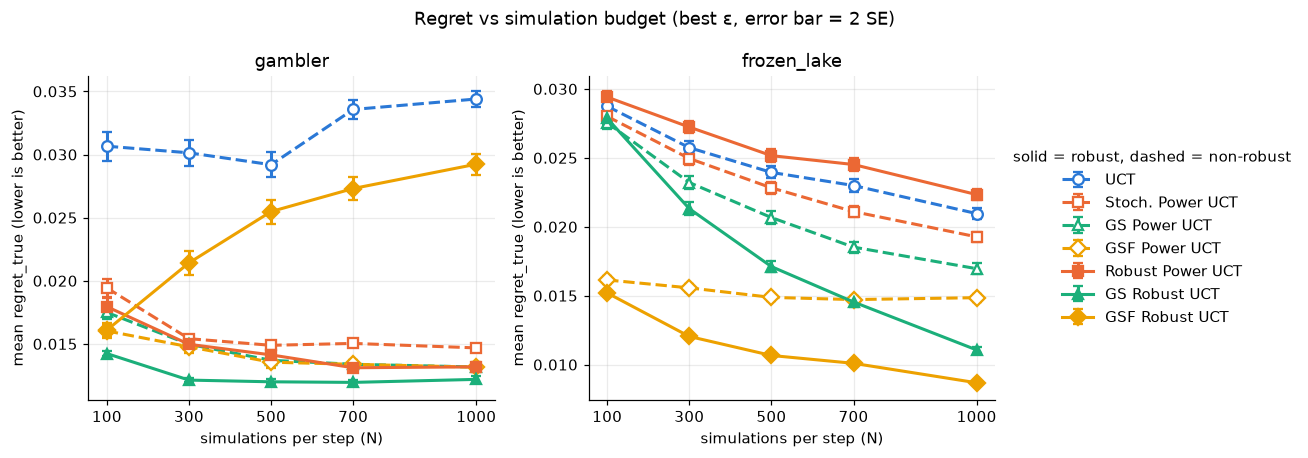

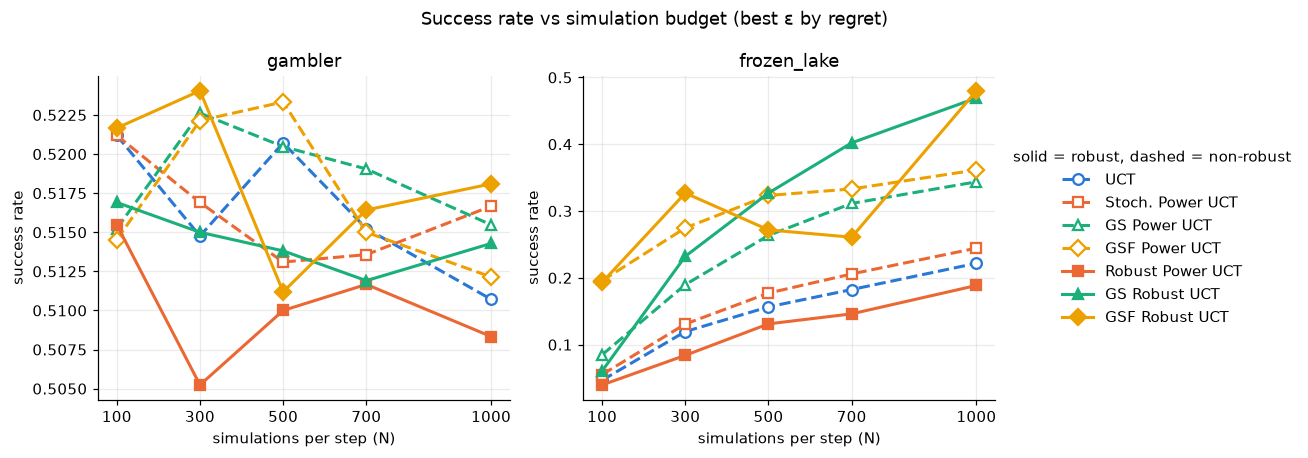

In [8]:
def by_sims(metric, ylabel, title, data=best, err=None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, env in zip(axes, ENVS):
        for name in ORDER:
            d = data[(data.env == env) & (data.name == name)].sort_values("sims")
            if d.empty:
                continue
            ax.errorbar(d.sims, d[metric], yerr=None if err is None else 2 * d[err], label=name,
                        capsize=3, **STYLE[name])
        ax.set_title(env); ax.set_xlabel("simulations per step (N)"); ax.set_ylabel(ylabel)
        ax.set_xticks(SIMS)
    axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False,
                   title="solid = robust, dashed = non-robust")
    fig.suptitle(title); fig.tight_layout(); plt.show()

by_sims("regret", "mean regret_true (lower is better)", "Regret vs simulation budget (best ε, error bar = 2 SE)", err="regret_se")
by_sims("success", "success rate", "Success rate vs simulation budget (best ε by regret)")

### Robustness: regret across the real environment θ_exec

Budget N = 700 (the largest budget complete for every method), best ε per method, mean over θ_plan.
For Gambler, p_h < 0.5 is the unfavourable game (optimal play = bold bets) and p_h > 0.5 the favourable one (optimal = small bets).

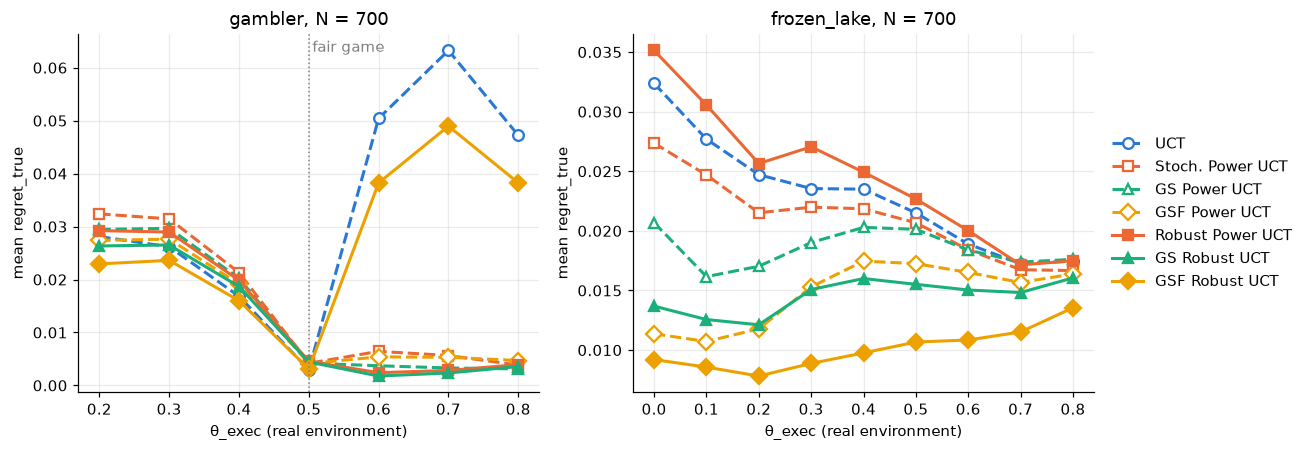


=== gambler: worst-case regret over all (θ_plan, θ_exec) pairs, best ε


sims,100,300,500,700,1000
name,,,,,
UCT,0.1019,0.1184,0.1178,0.1684,0.1807
Stoch. Power UCT,0.0364,0.0359,0.0358,0.0358,0.0360
GS Power UCT,0.0356,0.0337,0.0319,0.0316,0.0320
GSF Power UCT,0.0338,0.0314,0.0304,0.0301,0.0300
Robust Power UCT,0.0338,0.0329,0.0348,0.0351,0.0344
GS Robust UCT,0.0353,0.0303,0.0289,0.0290,0.0296
GSF Robust UCT,0.0320,0.0808,0.1229,0.1429,0.1650



=== frozen_lake: worst-case regret over all (θ_plan, θ_exec) pairs, best ε


sims,100,300,500,700,1000
name,,,,,
UCT,0.0496,0.0431,0.0416,0.0403,0.0344
Stoch. Power UCT,0.0475,0.0447,0.0338,0.0326,0.0254
GS Power UCT,0.0475,0.0360,0.0284,0.0246,0.0222
GSF Power UCT,0.0199,0.0191,0.0180,0.0185,0.0195
Robust Power UCT,0.0532,0.0461,0.0398,0.0392,0.0335
GS Robust UCT,0.0471,0.0303,0.0247,0.0184,0.0159
GSF Robust UCT,0.0196,0.0155,0.0147,0.0142,0.0143


In [9]:
N = 700
sel = best[best.sims == N][["env", "name", "eps"]]
D = df[df.sims == N].merge(sel, on=["env", "name", "eps"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, env in zip(axes, ENVS):
    for name in ORDER:
        d = D[(D.env == env) & (D.name == name)].groupby("theta_exec").mean_regret_true.mean()
        ax.plot(d.index, d.values, label=name, **STYLE[name])
    ax.set_title(f"{env}, N = {N}"); ax.set_xlabel("θ_exec (real environment)"); ax.set_ylabel("mean regret_true")
axes[0].axvline(0.5, color="gray", lw=1, ls=":"); axes[0].text(0.505, axes[0].get_ylim()[1] * 0.95, "fair game", color="gray")
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
fig.tight_layout(); plt.show()

for env in ENVS:
    print(f"\n=== {env}: worst-case regret over all (θ_plan, θ_exec) pairs, best ε")
    display(best[best.env == env].pivot(index="name", columns="sims", values="worst_regret").reindex(ORDER).round(4))

### Per-pair results: regret_true for each (θ_plan, θ_exec)

One table per (environment, N). Rows = (θ_plan, θ_exec): θ_plan is the model the planner uses, θ_exec the real environment the episode runs in.
Columns = methods; a robust method uses its best ε at that N (shown in the header). Cell = mean regret_true over 100 seeds × 2 episodes (smaller is better); the best method of each row is marked ★.
The last row is the mean over all pairs (same number as the Main Comparison table). The tables are also written to `results/pair_tables/<env>_sims<N>.csv`.

In [10]:
os.makedirs(f"{ROOT}/pair_tables", exist_ok=True)

def pair_table(env, N, metric="mean_regret_true"):
    sel = best[(best.env == env) & (best.sims == N)]
    cols = {}
    for name in ORDER:
        r = sel[sel.name == name]
        if r.empty:
            continue
        eps = r.eps.iloc[0]
        d = df[(df.env == env) & (df.sims == N) & (df.name == name) & (df.eps == eps)]
        label = name if eps == "-" else f"{name} [ε={eps}]"
        cols[label] = d.set_index(["theta_plan", "theta_exec"])[metric]
    t = pd.DataFrame(cols).sort_index()
    t.index.names = ["θ_plan", "θ_exec"]
    t.loc[("mean", "all"), :] = t.mean()
    return t

def mark(t, f, best_col):
    # string view: best method of each row marked with ★
    out = t.apply(lambda col: col.map(lambda v: "–" if pd.isna(v) else f.format(v)))
    for idx, c in best_col.items():
        out.loc[idx, c] += " ★"
    return out

for env in ENVS:
    for N in SIMS:
        t = pair_table(env, N)
        t.to_csv(f"{ROOT}/pair_tables/{env}_sims{N}.csv")
        print(f"\n=== {env}, N = {N}: regret_true per (θ_plan, θ_exec)")
        display(mark(t, "{:.4f}", t.idxmin(axis=1)))


=== gambler, N = 100: regret_true per (θ_plan, θ_exec)


UCT Stoch. Power UCT GS Power UCT GSF Power UCT Robust Power UCT [ε=0.2] GS Robust UCT [ε=0.05] GSF Robust UCT [ε=0.005]
θ_plan θ_exec                                                                                                                               
0.4    0.2     0.0246 ★           0.0364       0.0356        0.0338                   0.0337                 0.0353                   0.0320
       0.3     0.0223 ★           0.0337       0.0333        0.0319                   0.0323                 0.0339                   0.0316
       0.4     0.0138 ★           0.0213       0.0214        0.0211                   0.0208                 0.0222                   0.0204
       0.5     0.0024 ★           0.0039       0.0043        0.0044                   0.0042                 0.0047                   0.0042
       0.6       0.0792           0.0257       0.0183        0.0171                   0.0240               0.0067 ★                   0.0219
       0.7       0.1019           0.0296       0.0200        0.0198                   0.0281               0.0059 ★                   0.0238
       0.8       0.0767           0.0219       0.0143        0.0141                   0.0207               0.0052 ★                   0.0188
0.6    0.2       0.0384           0.0350       0.0330        0.0294                   0.0338                 0.0293                 0.0282 ★
       0.3       0.0354           0.0334       0.0323        0.0287                   0.0325                 0.0290                 0.0279 ★
       0.4       0.0223           0.0219       0.0214        0.0200                   0.0220                 0.0200                 0.0194 ★
       0.5     0.0039 ★           0.0043       0.0043        0.0043                   0.0047                 0.0045                   0.0042
       0.6       0.0259           0.0077       0.0063        0.0033                   0.0057                 0.0023                 0.0019 ★
       0.7       0.0282           0.0062       0.0049        0.0025                   0.0067                 0.0023                 0.0019 ★
       0.8       0.0192           0.0043       0.0042        0.0030                   0.0063                 0.0036                 0.0029 ★
0.8    0.2       0.0366           0.0326       0.0331        0.0304                   0.0304                 0.0289                 0.0286 ★
       0.3       0.0355           0.0322       0.0326        0.0304                   0.0299                 0.0294                 0.0291 ★
       0.4       0.0231           0.0219       0.0217        0.0212                   0.0202                 0.0207                 0.0201 ★
       0.5       0.0040           0.0039       0.0039        0.0038                   0.0042                 0.0045                 0.0036 ★
       0.6       0.0196           0.0132       0.0104        0.0081                   0.0059               0.0033 ★                   0.0078
       0.7       0.0196           0.0120       0.0081        0.0061                   0.0057               0.0033 ★                   0.0064
       0.8       0.0113           0.0068       0.0041      0.0032 ★                   0.0053                 0.0038                   0.0032
mean   all       0.0307           0.0194       0.0175        0.0160                   0.0179               0.0142 ★                   0.0161


=== gambler, N = 300: regret_true per (θ_plan, θ_exec)


UCT Stoch. Power UCT GS Power UCT GSF Power UCT Robust Power UCT [ε=0.1] GS Robust UCT [ε=0.05] GSF Robust UCT [ε=0.005]
θ_plan θ_exec                                                                                                                               
0.4    0.2     0.0218 ★           0.0359       0.0337        0.0314                   0.0329                 0.0303                   0.0244
       0.3     0.0201 ★           0.0343       0.0324        0.0302                   0.0323                 0.0296                   0.0226
       0.4     0.0123 ★           0.0223       0.0217        0.0202                   0.0209                 0.0203                   0.0143
       0.5     0.0021 ★           0.0045       0.0045        0.0045                   0.0044                 0.0050                   0.0028
       0.6       0.0897           0.0102       0.0069        0.0161                   0.0146               0.0027 ★                   0.0642
       0.7       0.1184           0.0099       0.0070        0.0197                   0.0171               0.0032 ★                   0.0808
       0.8       0.0906           0.0069       0.0060        0.0155                   0.0136               0.0050 ★                   0.0617
0.6    0.2       0.0383           0.0310       0.0302        0.0257                   0.0292               0.0254 ★                   0.0274
       0.3       0.0357           0.0309       0.0300        0.0258                   0.0299               0.0255 ★                   0.0274
       0.4       0.0227           0.0212       0.0201        0.0183                   0.0202               0.0183 ★                   0.0193
       0.5     0.0042 ★           0.0043       0.0042        0.0043                   0.0046                 0.0044                   0.0042
       0.6       0.0188           0.0041       0.0036        0.0010                   0.0028               0.0007 ★                   0.0023
       0.7       0.0195           0.0040       0.0026        0.0016                   0.0032               0.0015 ★                   0.0018
       0.8       0.0113           0.0033     0.0027 ★        0.0030                   0.0041                 0.0035                   0.0028
0.8    0.2       0.0352           0.0307       0.0319        0.0288                   0.0272               0.0255 ★                   0.0284
       0.3       0.0342           0.0301       0.0320        0.0296                   0.0271               0.0260 ★                   0.0301
       0.4       0.0225           0.0208       0.0212        0.0209                   0.0192               0.0189 ★                   0.0209
       0.5       0.0039           0.0037     0.0037 ★        0.0038                   0.0044                 0.0043                   0.0038
       0.6       0.0134           0.0074       0.0094        0.0051                   0.0017               0.0008 ★                   0.0055
       0.7       0.0120           0.0056       0.0074        0.0033                   0.0018               0.0012 ★                   0.0034
       0.8       0.0062           0.0027       0.0034      0.0015 ★                   0.0031                 0.0028                   0.0016
mean   all       0.0301           0.0154       0.0150        0.0148                   0.0150               0.0121 ★                   0.0214


=== gambler, N = 500: regret_true per (θ_plan, θ_exec)


UCT Stoch. Power UCT GS Power UCT GSF Power UCT Robust Power UCT [ε=0.1] GS Robust UCT [ε=0.05] GSF Robust UCT [ε=0.005]
θ_plan θ_exec                                                                                                                             
0.4    0.2     0.0209           0.0358       0.0319        0.0304                   0.0348                 0.0289                 0.0183 ★
       0.3     0.0182           0.0337       0.0312        0.0296                   0.0335                 0.0289                 0.0169 ★
       0.4     0.0110           0.0218       0.0213        0.0196                   0.0213                 0.0194                 0.0105 ★
       0.5     0.0019           0.0045       0.0047        0.0046                   0.0046                 0.0049                 0.0019 ★
       0.6     0.0913           0.0083       0.0049        0.0097                   0.0102               0.0034 ★                   0.0949
       0.7     0.1178           0.0084     0.0049 ★        0.0115                   0.0120                 0.0050                   0.1229
       0.8     0.0899           0.0062     0.0050 ★        0.0101                   0.0100                 0.0060                   0.0947
0.6    0.2     0.0367           0.0308       0.0276      0.0247 ★                   0.0288                 0.0247                   0.0269
       0.3     0.0358           0.0313       0.0275        0.0255                   0.0293               0.0249 ★                   0.0270
       0.4     0.0231           0.0206       0.0192        0.0184                   0.0197               0.0176 ★                   0.0194
       0.5     0.0043         0.0042 ★       0.0043        0.0043                   0.0045                 0.0043                   0.0043
       0.6     0.0139           0.0034       0.0024        0.0007                   0.0019               0.0005 ★                   0.0017
       0.7     0.0145           0.0035       0.0022      0.0010 ★                   0.0024                 0.0014                   0.0015
       0.8     0.0092           0.0034       0.0029        0.0028                   0.0037                 0.0035                 0.0027 ★
0.8    0.2     0.0364           0.0287       0.0294        0.0284                   0.0254               0.0248 ★                   0.0287
       0.3     0.0345           0.0302       0.0306        0.0292                   0.0261               0.0258 ★                   0.0299
       0.4     0.0225           0.0208       0.0211        0.0201                   0.0190               0.0185 ★                   0.0203
       0.5     0.0040           0.0038       0.0037        0.0036                   0.0043                 0.0041                 0.0036 ★
       0.6     0.0119           0.0063       0.0065        0.0056                 0.0008 ★                 0.0014                   0.0049
       0.7     0.0101           0.0047       0.0046        0.0033                 0.0014 ★                 0.0014                   0.0028
       0.8     0.0051           0.0022       0.0020        0.0015                   0.0031                 0.0025                 0.0012 ★
mean   all     0.0292           0.0149       0.0137        0.0136                   0.0141               0.0120 ★                   0.0255

... (10 outputs left out)


=== frozen_lake, N = 700: regret_true per (θ_plan, θ_exec)


UCT Stoch. Power UCT GS Power UCT GSF Power UCT Robust Power UCT [ε=0.1] GS Robust UCT [ε=0.2] GSF Robust UCT [ε=0.3]
θ_plan θ_exec                                                                                                                          
0.1    0.0     0.0215           0.0230       0.0246        0.0118                   0.0380                0.0184               0.0090 ★
       0.1     0.0206           0.0193       0.0168        0.0122                   0.0344                0.0162               0.0081 ★
       0.2     0.0217           0.0191       0.0180        0.0131                   0.0265                0.0151               0.0077 ★
       0.3     0.0219           0.0200       0.0207        0.0172                   0.0276                0.0170               0.0090 ★
       0.4     0.0233           0.0200       0.0216        0.0184                   0.0241                0.0162               0.0103 ★
       0.5     0.0214           0.0195       0.0215        0.0185                   0.0216                0.0175               0.0106 ★
       0.6     0.0184           0.0187       0.0186        0.0178                   0.0186                0.0158               0.0110 ★
       0.7     0.0166           0.0170       0.0174        0.0154                   0.0170                0.0152               0.0117 ★
       0.8     0.0171           0.0158       0.0178        0.0164                   0.0179                0.0169               0.0141 ★
0.2    0.0     0.0324           0.0235       0.0187        0.0092                   0.0297                0.0120               0.0090 ★
       0.1     0.0252           0.0196       0.0165        0.0091                   0.0270                0.0120               0.0086 ★
       0.2     0.0225           0.0195       0.0188        0.0106                   0.0242                0.0127               0.0075 ★
       0.3     0.0224           0.0194       0.0202        0.0146                   0.0261                0.0160               0.0088 ★
       0.4     0.0230           0.0208       0.0213        0.0166                   0.0254                0.0170               0.0090 ★
       0.5     0.0219           0.0206       0.0205        0.0167                   0.0225                0.0161               0.0098 ★
       0.6     0.0192           0.0177       0.0180        0.0164                   0.0204                0.0158               0.0097 ★
       0.7     0.0173           0.0163       0.0174        0.0155                   0.0169                0.0152               0.0111 ★
       0.8     0.0181           0.0174       0.0177        0.0168                   0.0174                0.0161               0.0126 ★
0.3    0.0     0.0353           0.0316       0.0174        0.0106                   0.0336                0.0140               0.0085 ★
       0.1     0.0301           0.0272       0.0154        0.0098                   0.0301                0.0128               0.0084 ★
       0.2     0.0270           0.0225       0.0166        0.0118                   0.0265                0.0111               0.0078 ★
       0.3     0.0253           0.0243       0.0179        0.0156                   0.0269                0.0140               0.0091 ★
       0.4     0.0239           0.0230       0.0202        0.0180                   0.0255                0.0149               0.0097 ★
       0.5     0.0214           0.0200       0.0205        0.0173                   0.0241                0.0138               0.0109 ★
       0.6     0.0191           0.0183       0.0192        0.0163                   0.0205                0.0141               0.0110 ★
       0.7     0.0174           0.0164       0.0174        0.0163                   0.0176                0.0144               0.0116 ★
       0.8     0.0171           0.0170       0.0174        0.0156                   0.0168                0.0162               0.0134 ★
0.4    0.0     0.0403           0.0313       0.0220        0.0139         


=== frozen_lake, N = 1000: regret_true per (θ_plan, θ_exec)


UCT Stoch. Power UCT GS Power UCT GSF Power UCT Robust Power UCT [ε=tuned] GS Robust UCT [ε=0.2] GSF Robust UCT [ε=0.2]
θ_plan θ_exec                                                                                                                            
0.1    0.0     0.0195           0.0152       0.0172        0.0078                     0.0288                0.0107               0.0022 ★
       0.1     0.0206           0.0168       0.0150        0.0113                     0.0256                0.0081               0.0025 ★
       0.2     0.0159           0.0159       0.0165        0.0136                     0.0216                0.0075               0.0031 ★
       0.3     0.0191           0.0188       0.0180        0.0178                     0.0241                0.0113               0.0079 ★
       0.4     0.0206           0.0201       0.0222        0.0195                     0.0226                0.0130               0.0114 ★
       0.5     0.0203           0.0188       0.0212        0.0187                     0.0211                0.0138               0.0125 ★
       0.6     0.0180           0.0176       0.0200        0.0173                     0.0193                0.0147               0.0138 ★
       0.7     0.0176           0.0167       0.0187        0.0163                     0.0171                0.0143               0.0138 ★
       0.8     0.0177           0.0170       0.0178        0.0163                     0.0170                0.0153               0.0143 ★
0.2    0.0     0.0258           0.0190       0.0138        0.0111                     0.0285                0.0064               0.0017 ★
       0.1     0.0215           0.0180       0.0094        0.0092                     0.0231                0.0062               0.0019 ★
       0.2     0.0204           0.0174       0.0122        0.0111                     0.0229                0.0070               0.0028 ★
       0.3     0.0198           0.0216       0.0183        0.0163                     0.0225                0.0090               0.0076 ★
       0.4     0.0217           0.0223       0.0212        0.0184                     0.0225                0.0124               0.0102 ★
       0.5     0.0210           0.0207       0.0198        0.0171                     0.0216                0.0146               0.0122 ★
       0.6     0.0190           0.0186       0.0185        0.0174                     0.0196                0.0143               0.0134 ★
       0.7     0.0177           0.0163       0.0170        0.0158                     0.0171                0.0138               0.0126 ★
       0.8     0.0171           0.0175       0.0185        0.0169                     0.0169                0.0153               0.0142 ★
0.3    0.0     0.0259           0.0219       0.0144        0.0094                     0.0335                0.0069               0.0025 ★
       0.1     0.0236           0.0209       0.0155        0.0111                     0.0244                0.0069               0.0020 ★
       0.2     0.0214           0.0190       0.0135        0.0118                     0.0239                0.0061               0.0030 ★
       0.3     0.0223           0.0220       0.0183        0.0151                     0.0237                0.0091               0.0076 ★
       0.4     0.0235           0.0210       0.0201        0.0177                     0.0238                0.0119               0.0103 ★
       0.5     0.0208           0.0218       0.0194        0.0181                     0.0221                0.0130               0.0120 ★
       0.6     0.0193           0.0190       0.0184        0.0177                     0.0193              0.0128 ★                 0.0128
       0.7     0.0160           0.0164       0.0179        0.0164                     0.0173                0.0146               0.0127 ★
       0.8     0.0175           0.0179       0.0189        0.0170                     0.0169                0.0150               0.0135 ★
0.4    0.0     0

Same layout for **success rate** (larger is better), at N = 1000.

In [11]:
for env in ENVS:
    t = pair_table(env, 1000, "success_rate")
    print(f"\n=== {env}, N = 1000: success rate per (θ_plan, θ_exec)")
    display(mark(t, "{:.3f}", t.idxmax(axis=1)))


=== gambler, N = 1000: success rate per (θ_plan, θ_exec)


UCT Stoch. Power UCT GS Power UCT GSF Power UCT Robust Power UCT [ε=0.1] GS Robust UCT [ε=0.05] GSF Robust UCT [ε=0.005]
θ_plan θ_exec                                                                                                                              
0.4    0.2     0.180 ★            0.015        0.010         0.015                    0.015                  0.005                    0.155
       0.3     0.290 ★            0.085        0.055         0.060                    0.075                  0.035                    0.290
       0.4     0.425 ★            0.250        0.200         0.200                    0.230                  0.185                    0.405
       0.5       0.510          0.560 ★        0.480         0.525                    0.530                  0.505                    0.505
       0.6       0.590            0.785        0.790         0.785                    0.785                0.825 ★                    0.615
       0.7       0.735            0.935        0.955         0.925                    0.945                0.960 ★                    0.750
       0.8       0.845          0.985 ★        0.985         0.975                    0.980                  0.980                    0.860
0.6    0.2     0.040 ★            0.015        0.010         0.010                    0.005                  0.005                    0.005
       0.3     0.125 ★            0.085        0.070         0.065                    0.040                  0.025                    0.060
       0.4     0.265 ★            0.210        0.200         0.195                    0.155                  0.165                    0.205
       0.5       0.535            0.495      0.540 ★         0.495                    0.500                  0.495                    0.515
       0.6       0.730            0.830        0.830         0.860                    0.845                0.880 ★                    0.835
       0.7       0.910            0.950        0.975         0.985                    0.975                0.990 ★                    0.975
       0.8       0.975            0.990      1.000 ★         1.000                    0.995                  1.000                    1.000
0.8    0.2     0.040 ★            0.035        0.025         0.035                    0.010                  0.015                    0.040
       0.3     0.160 ★            0.155        0.130         0.140                    0.035                  0.115                    0.125
       0.4       0.270          0.295 ★        0.285         0.265                    0.185                  0.245                    0.260
       0.5       0.500            0.510        0.545         0.510                    0.515                0.565 ★                    0.535
       0.6       0.730            0.740        0.805         0.785                  0.870 ★                  0.835                    0.795
       0.7       0.915            0.935        0.945         0.950                  0.985 ★                  0.975                    0.955
       0.8       0.955            0.990        0.990         0.975                  1.000 ★                  0.995                    0.995
mean   all       0.511            0.517        0.515         0.512                    0.508                  0.514                  0.518 ★


=== frozen_lake, N = 1000: success rate per (θ_plan, θ_exec)


UCT Stoch. Power UCT GS Power UCT GSF Power UCT Robust Power UCT [ε=tuned] GS Robust UCT [ε=0.2] GSF Robust UCT [ε=0.2]
θ_plan θ_exec                                                                                                                           
0.1    0.0     0.740            0.815        0.830         0.920                      0.515                 0.940                0.995 ★
       0.1     0.535            0.620        0.695         0.660                      0.450                 0.820                0.880 ★
       0.2     0.440            0.445        0.525         0.465                      0.265                 0.685                0.745 ★
       0.3     0.285            0.305        0.350         0.405                      0.195                 0.575                0.605 ★
       0.4     0.175            0.185        0.185         0.260                      0.180               0.490 ★                  0.445
       0.5     0.075            0.075        0.100         0.110                      0.080                 0.320                0.325 ★
       0.6     0.040            0.035        0.045         0.080                      0.020                 0.140                0.175 ★
       0.7     0.010            0.020        0.005         0.035                      0.015                 0.050                0.075 ★
       0.8     0.000            0.000        0.005         0.010                      0.005               0.035 ★                  0.005
0.2    0.0     0.655            0.735        0.875         0.900                      0.555                 0.975                1.000 ★
       0.1     0.555            0.565        0.815         0.780                      0.440                 0.845                0.880 ★
       0.2     0.370            0.445        0.605         0.500                      0.335                 0.760                0.775 ★
       0.3     0.305            0.285        0.445         0.410                      0.205               0.655 ★                  0.605
       0.4     0.195            0.195        0.245         0.235                      0.125                 0.440                0.475 ★
       0.5     0.110            0.090        0.110         0.150                      0.065                 0.280                0.315 ★
       0.6     0.015            0.065        0.045         0.105                      0.025                 0.150                0.160 ★
       0.7     0.025            0.015        0.005         0.020                      0.015               0.100 ★                  0.070
       0.8     0.010            0.000      0.030 ★         0.000                      0.000                 0.025                  0.000
0.3    0.0     0.580            0.670        0.840         0.915                      0.455                 0.980                0.995 ★
       0.1     0.420            0.540        0.670         0.730                      0.440                 0.900                0.905 ★
       0.2     0.395            0.320        0.550         0.615                      0.345               0.750 ★                  0.730
       0.3     0.235            0.240        0.415         0.490                      0.225                 0.605                0.680 ★
       0.4     0.140            0.170        0.285         0.330                      0.135               0.450 ★                  0.440
       0.5     0.055            0.080        0.165         0.210                      0.090                 0.325                0.335 ★
       0.6     0.080            0.055        0.075         0.100                      0.040               0.190 ★                  0.170
       0.7     0.010            0.030        0.050         0.035                      0.010               0.090 ★                  0.040
       0.8     0.010            0.005        0.005       0.015 ★                      0.005                 0.015                  0.005
0.4    0.0     0.445            0.615       

### Observations (data as of 04/11/2026)

**FrozenLake**
- Full merge wins clearly. GSF Robust UCT has the lowest regret at every budget (≈0.0152 at N=100 → 0.0087 at N=1000, ε=0.2), then GSF Power UCT at small N and GS Robust UCT at large N. Differences are many SE apart (SE ≈ 1e-4).
- Sample efficiency: GSF Robust UCT at N=100 (≈0.015) already beats every tree method at N=1000 (UCT 0.021, Stoch. Power 0.019, Robust Power 0.022).
- Robust Power UCT (tree) is the **worst** method on FrozenLake, worse than plain UCT at every budget, and its success rate is the lowest. With a tree, each (s, a) copy gets few samples, so the robust backup is pessimistic on noisy empirical transitions. Once states are merged (GS / GSF) the same robust backup turns into an improvement over the non-robust version.
- Worst case over pairs follows the same order: GSF Robust ≈ 0.014, GSF Power ≈ 0.019, tree methods 0.025-0.053.

**Gambler**
- Except UCT and GSF Robust UCT, all methods sit in a narrow band (0.012-0.019). Best: GS Robust UCT with ε=0.05 at every budget (0.0120-0.0142), then Robust Power UCT ε=0.1 and GS/GSF Power UCT (≈0.0132 at N=1000).
- **GSF Robust UCT breaks on Gambler, but only for θ_plan = 0.4** (see the per-pair tables): mean regret by θ_plan at N=1000 is 0.063 / 0.012 / 0.013 for θ_plan = 0.4 / 0.6 / 0.8; at θ_plan ≥ 0.6 it is as good as the best methods. With θ_plan = 0.4 the planning model is the unfavourable game, where bold bets are optimal; GSF Robust (like UCT) learns that plan-optimal policy well and then loses a lot when the real game is favourable (θ_exec ≥ 0.6, regret 0.12–0.17), while it is near-best when θ_exec ≤ 0.5. More simulations make it converge further to the plan-optimal policy, so regret grows with N. The ε grid (≤ 0.5, best 0.005) does not cover a mismatch 0.4 → 0.6+ in a way that changes the bet size. GSF Power UCT (same graph, no robust backup) stays at 0.016 for θ_plan = 0.4, so the robust backup matters: on Gambler the worst case of the TV ball is a lower p_h, which pushes the policy even further toward bold bets, i.e. away from what the favourable real game needs. So this looks like a model-mismatch + pessimism-direction effect, not only the 'worst case repeated through cycles' explanation first assumed; it still needs a check (e.g. root action distribution of GSF Robust vs GSF Power at θ_plan = 0.4).
- Success rate is ≈0.51 for all methods: it mostly reflects θ_exec, not the planner, so regret is the metric to use on Gambler.
- UCT is the worst on Gambler (0.03-0.034) and also gets worse with N.

---
# Ablation study

Two factors, each with the other held fixed:
- **Search structure**: tree → depth merge (GS) → full merge (GSF).
- **Backup**: non-robust (power mean) vs robust (TV ball), at the best ε.

In [12]:
for env in ENVS:
    t = best[(best.env == env) & (best.name != "UCT")].pivot_table(index="sims", columns=["robust", "structure"], values="regret")
    t = t.reindex(columns=pd.MultiIndex.from_product([[False, True], ["tree", "depth merge", "full merge"]]))
    gain = (t[False] - t[True]) / t[False] * 100
    print(f"\n=== {env}: regret by structure (columns) and backup (False = non-robust, True = robust)")
    display(t.round(4))
    print(f"{env}: regret reduction of the robust backup vs non-robust, same structure (%; > 0 = robust better)")
    display(gain.round(1))


=== gambler: regret by structure (columns) and backup (False = non-robust, True = robust)


False                          True                        
        tree depth merge full merge    tree depth merge full merge
sims                                                              
100   0.0194      0.0175     0.0160  0.0179      0.0142     0.0161
300   0.0154      0.0150     0.0148  0.0150      0.0121     0.0214
500   0.0149      0.0137     0.0136  0.0141      0.0120     0.0255
700   0.0150      0.0134     0.0134  0.0131      0.0120     0.0273
1000  0.0147      0.0132     0.0132  0.0132      0.0122     0.0292

gambler: regret reduction of the robust backup vs non-robust, same structure (%; > 0 = robust better)


,tree,depth merge,full merge
sims,,,
100,7.6,18.6,-0.4
300,2.9,19.0,-45.0
500,5.1,12.4,-88.0
700,12.8,10.7,-104.0
1000,10.2,7.4,-122.2



=== frozen_lake: regret by structure (columns) and backup (False = non-robust, True = robust)


False                          True                        
        tree depth merge full merge    tree depth merge full merge
sims                                                              
100   0.0280      0.0275     0.0161  0.0294      0.0279     0.0152
300   0.0250      0.0232     0.0156  0.0272      0.0213     0.0120
500   0.0228      0.0207     0.0149  0.0252      0.0171     0.0107
700   0.0211      0.0185     0.0147  0.0245      0.0145     0.0101
1000  0.0193      0.0170     0.0149  0.0223      0.0111     0.0087

frozen_lake: regret reduction of the robust backup vs non-robust, same structure (%; > 0 = robust better)


,tree,depth merge,full merge
sims,,,
100,-5.0,-1.2,5.9
300,-9.1,8.2,22.6
500,-10.2,17.2,28.3
700,-16.2,21.5,31.4
1000,-15.9,34.8,41.6


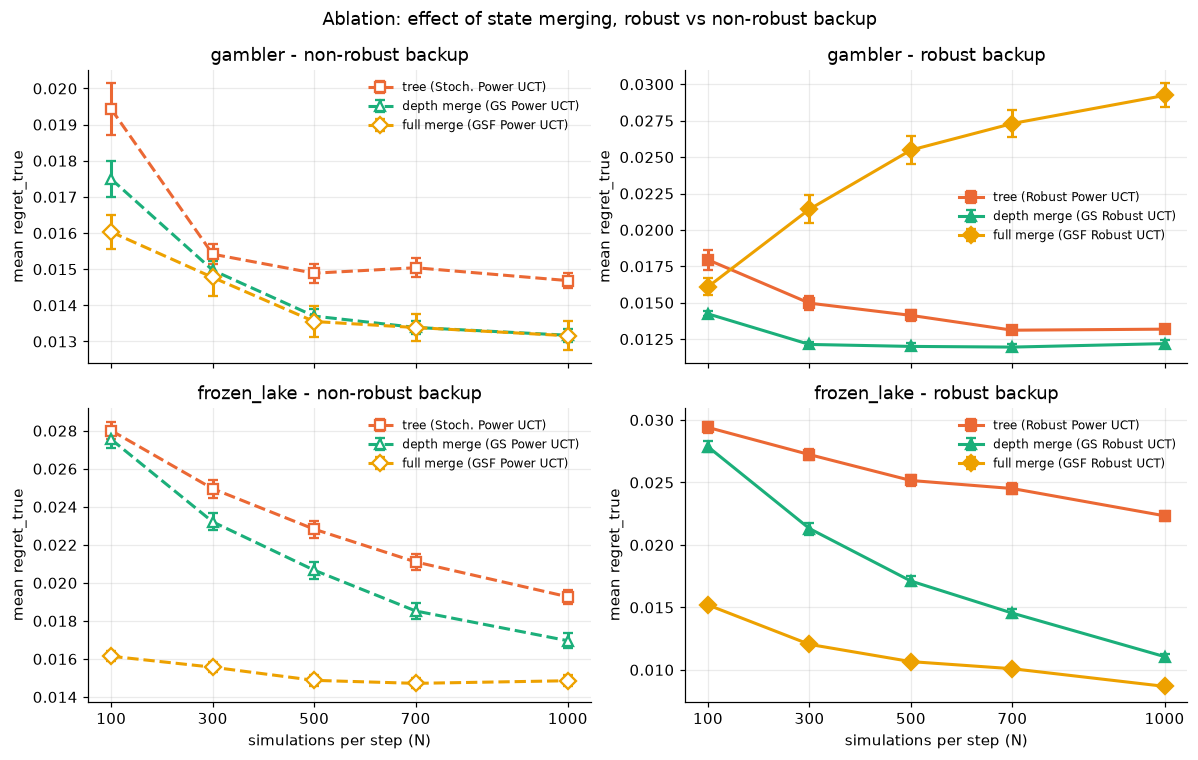

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for i, env in enumerate(ENVS):
    for j, robust in enumerate([False, True]):
        ax = axes[i, j]
        for name, s, r in ALGOS.values():
            if r != robust or s == "UCT":
                continue
            d = best[(best.env == env) & (best.name == name)].sort_values("sims")
            ax.errorbar(d.sims, d.regret, yerr=2 * d.regret_se, label=f"{s} ({name})", capsize=3, **STYLE[name])
        ax.set_title(f"{env} - {'robust' if robust else 'non-robust'} backup")
        ax.set_ylabel("mean regret_true"); ax.legend(frameon=False, fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("simulations per step (N)"); ax.set_xticks(SIMS)
fig.suptitle("Ablation: effect of state merging, robust vs non-robust backup"); fig.tight_layout(); plt.show()

### Observations

- **Merging states helps on both environments with the non-robust backup** (tree → GS → GSF lowers regret at every N on FrozenLake; on Gambler the gain is smaller, 0.015 → 0.013 at N=1000).
- **The robust backup helps only on top of merging.** FrozenLake: robust is worse than non-robust on the tree (negative %), but better with depth merge and full merge, and the gain grows with N. Gambler: robust helps with tree and depth merge at small ε, but hurts with full merge (the θ_plan = 0.4 effect above).
- This fits the thesis idea (sharing samples makes the empirical model used by the robust backup less noisy), but on Gambler full merge plus robust backup needs a fix before it can be claimed in general (e.g. apply the worst case once per state per backup, or depth-limited merging as in GS).

---
# Sensitivity Analysis

### Uncertainty radius ε

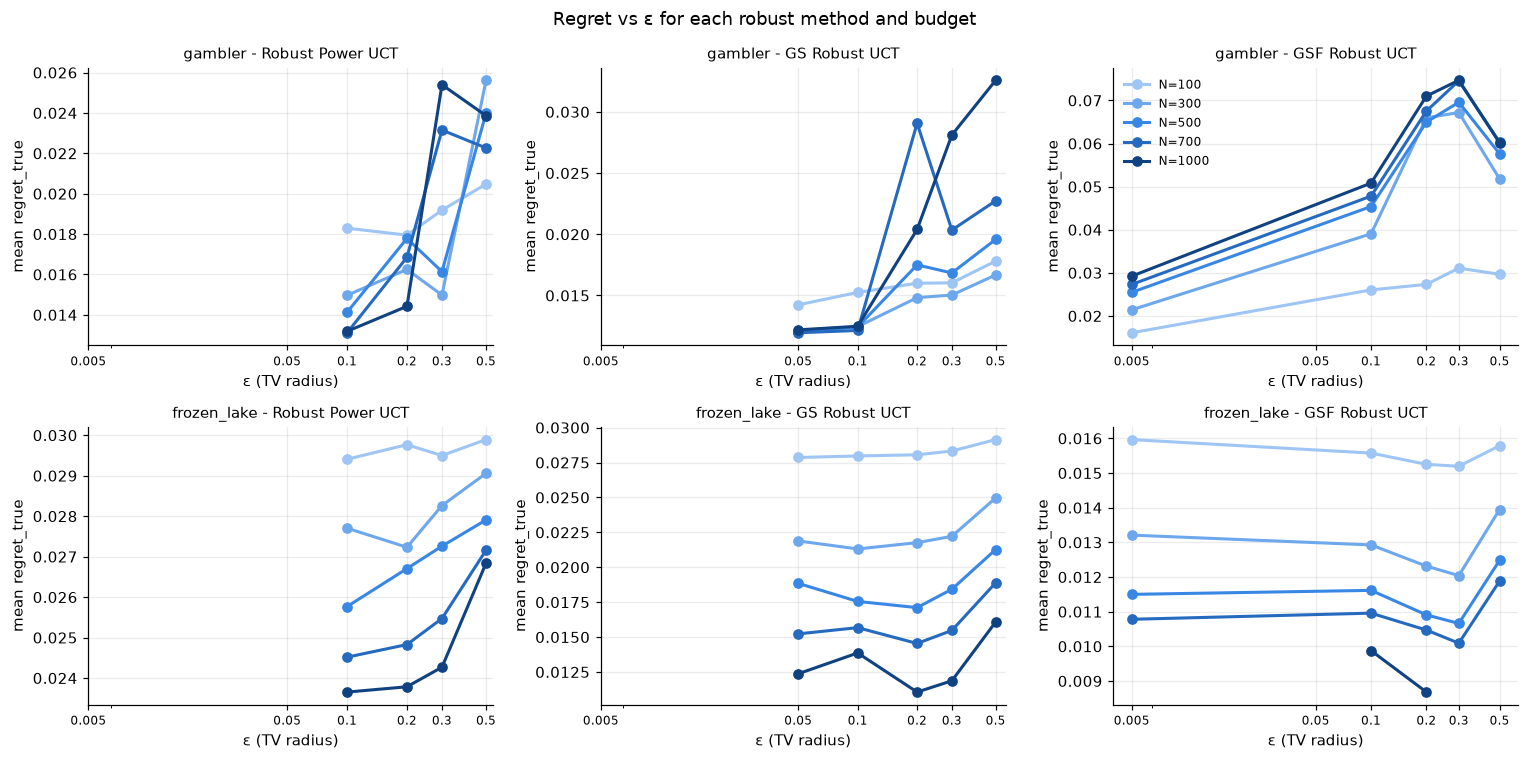

In [14]:
robust_names = [v[0] for v in ALGOS.values() if v[2]]
R = A[A.robust & (A.eps != "tuned")].assign(e=lambda x: x.eps.astype(float))
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
blues = {100: "#9ec5f4", 300: "#6da7ec", 500: "#3987e5", 700: "#256abf", 1000: "#104281"}  # sequential: one hue, light -> dark
for i, env in enumerate(ENVS):
    for j, name in enumerate(robust_names):
        ax = axes[i, j]
        for n in SIMS:
            d = R[(R.env == env) & (R.name == name) & (R.sims == n)].sort_values("e")
            if len(d):
                ax.plot(d.e, d.regret, marker="o", lw=2, color=blues[n], label=f"N={n}")
        ax.set_title(f"{env} - {name}", fontsize=10); ax.set_xlabel("ε (TV radius)"); ax.set_ylabel("mean regret_true")
        ax.set_xscale("symlog", linthresh=0.05); ax.set_xticks([0.005, 0.05, 0.1, 0.2, 0.3, 0.5]); ax.set_xticklabels(["0.005", "0.05", "0.1", "0.2", "0.3", "0.5"], fontsize=8)
axes[0, 2].legend(frameon=False, fontsize=8)
fig.suptitle("Regret vs ε for each robust method and budget"); fig.tight_layout(); plt.show()

### Hyper-parameters selected by tune.py (exploration constant c, power p)

In [15]:
sel = A.assign(cfg=lambda x: "c=" + x.c.astype(str) + ", p=" + x.p.astype(str))
for env in ENVS:
    print(f"\n=== {env}")
    display(sel[sel.env == env].pivot_table(index=["name", "eps"], columns="sims", values="cfg", aggfunc="first"))
share = (A.c == A.c.max()).mean() * 100
print(f"c = {A.c.max()} (upper end of the grid) is selected in {share:.0f}% of all runs; p = inf in {(A.p == np.inf).mean()*100:.0f}%.")


=== gambler


sims                             100             300            500            700            1000
name             eps                                                                              
GS Power UCT     -       c=2.0, p=inf   c=2.0, p=32.0   c=2.0, p=inf   c=2.0, p=inf   c=1.0, p=inf
GS Robust UCT    0.05    c=2.0, p=inf    c=2.0, p=inf   c=2.0, p=inf   c=1.0, p=inf   c=2.0, p=inf
                 0.1     c=1.0, p=inf    c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf
                 0.2     c=1.0, p=inf    c=1.0, p=inf   c=1.0, p=inf  c=2.0, p=16.0   c=2.0, p=inf
                 0.3     c=2.0, p=8.0    c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf
                 0.5     c=2.0, p=inf    c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf   c=1.0, p=inf
GSF Power UCT    -       c=0.5, p=inf    c=0.5, p=inf   c=2.0, p=inf   c=1.0, p=inf   c=2.0, p=inf
GSF Robust UCT   0.005   c=1.0, p=inf    c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf
                 0.1     c=0.5, p=inf    c=2.0, p=inf   c=2.0, p=inf   c=0.5, p=inf  c=0.25, p=inf
                 0.2     c=2.0, p=inf   c=2.0, p=32.0   c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf
                 0.3     c=2.0, p=inf  c=0.25, p=32.0   c=2.0, p=inf   c=2.0, p=8.0  c=1.0, p=16.0
                 0.5     c=2.0, p=inf    c=1.0, p=inf   c=2.0, p=inf  c=2.0, p=16.0   c=2.0, p=8.0
Robust Power UCT 0.1    c=2.0, p=16.0   c=2.0, p=16.0  c=2.0, p=16.0   c=2.0, p=inf   c=2.0, p=inf
                 0.2    c=2.0, p=16.0    c=2.0, p=8.0  c=1.0, p=32.0   c=2.0, p=8.0  c=2.0, p=32.0
                 0.3     c=2.0, p=inf    c=2.0, p=inf  c=2.0, p=16.0   c=0.5, p=inf   c=0.5, p=inf
                 0.5    c=2.0, p=16.0    c=0.5, p=4.0  c=0.5, p=16.0   c=0.5, p=inf   c=0.5, p=inf
                 tuned   c=2.0, p=inf    c=1.0, p=inf  c=2.0, p=16.0  c=1.0, p=32.0   c=2.0, p=inf
Stoch. Power UCT -       c=0.5, p=inf    c=2.0, p=inf   c=1.0, p=inf  c=2.0, p=32.0  c=2.0, p=32.0


=== frozen_lake


sims                             100            300            500            700            1000
name             eps                                                                             
GS Power UCT     -       c=0.5, p=inf   c=1.0, p=inf   c=0.5, p=inf   c=0.5, p=inf   c=0.5, p=inf
GS Robust UCT    0.05    c=2.0, p=inf  c=2.0, p=16.0   c=2.0, p=inf  c=2.0, p=32.0  c=2.0, p=32.0
                 0.1     c=2.0, p=8.0   c=2.0, p=8.0  c=2.0, p=32.0   c=2.0, p=inf   c=2.0, p=inf
                 0.2     c=2.0, p=8.0  c=2.0, p=32.0  c=2.0, p=32.0  c=2.0, p=32.0  c=2.0, p=16.0
                 0.3     c=1.0, p=8.0  c=2.0, p=32.0   c=2.0, p=inf   c=2.0, p=inf  c=2.0, p=32.0
                 0.5     c=2.0, p=8.0  c=1.0, p=32.0   c=1.0, p=inf   c=1.0, p=inf   c=1.0, p=inf
GSF Power UCT    -       c=1.0, p=inf   c=2.0, p=inf   c=2.0, p=inf   c=1.0, p=inf   c=1.0, p=inf
GSF Robust UCT   0.005   c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf            NaN
                 0.1     c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf
                 0.2    c=2.0, p=32.0   c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf  c=2.0, p=32.0
                 0.3     c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf   c=2.0, p=inf            NaN
                 0.5    c=1.0, p=32.0   c=2.0, p=inf  c=0.25, p=inf  c=0.25, p=inf            NaN
Robust Power UCT 0.1     c=2.0, p=inf   c=2.0, p=1.0  c=2.0, p=32.0  c=2.0, p=32.0  c=2.0, p=32.0
                 0.2    c=2.0, p=32.0  c=2.0, p=16.0   c=2.0, p=4.0   c=2.0, p=4.0  c=2.0, p=32.0
                 0.3     c=2.0, p=inf  c=0.5, p=32.0   c=2.0, p=4.0   c=2.0, p=4.0   c=2.0, p=4.0
                 0.5     c=2.0, p=inf  c=2.0, p=16.0   c=2.0, p=inf   c=2.0, p=4.0  c=2.0, p=32.0
                 tuned  c=2.0, p=16.0   c=2.0, p=inf   c=1.0, p=1.0  c=2.0, p=32.0   c=2.0, p=inf
Stoch. Power UCT -      c=0.25, p=inf  c=0.25, p=inf  c=0.5, p=32.0  c=0.25, p=8.0  c=0.25, p=8.0

c = 2.0 (upper end of the grid) is selected in 68% of all runs; p = inf in 59%.


### Time per search (median over pairs; indicative only, see caveat 2)

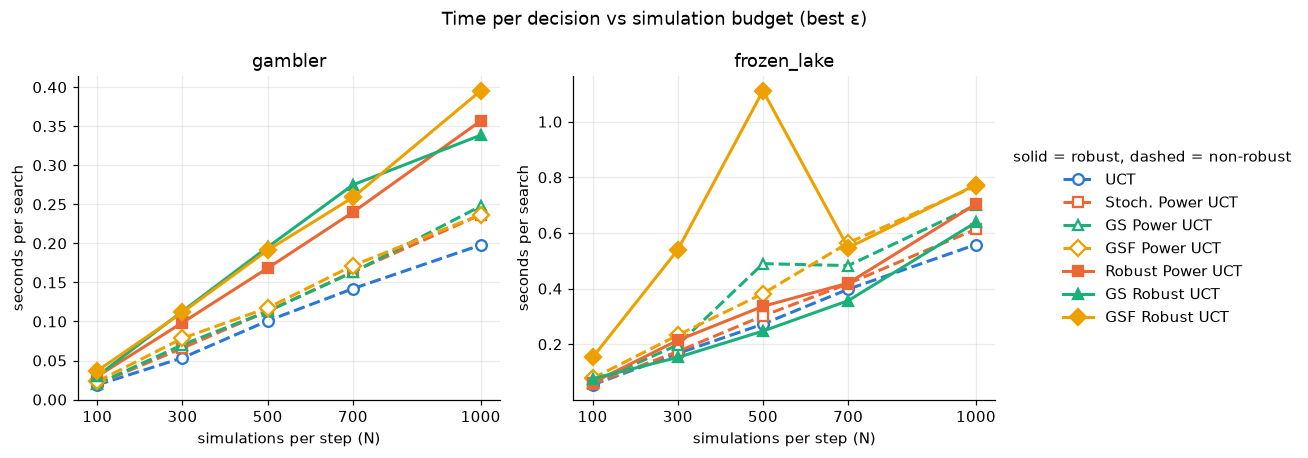

In [16]:
by_sims("time", "seconds per search", "Time per decision vs simulation budget (best ε)")

### Observations

- **ε**: on FrozenLake regret is flat for ε ∈ [0.05, 0.3] and rises at 0.5 for every robust method, so the method is not sensitive to ε in a wide range. On Gambler small ε is best (0.05-0.1); for GS Robust and Robust Power UCT regret grows with ε at large N; GSF Robust is bad at every ε ≥ 0.1.
- **c**: the largest value of the grid (c = 2) is chosen in most runs, so the grid is too narrow: the best c may be larger. Suggest re-tuning with c ∈ {2, 4, 8} for at least the main methods.
- **p**: p = ∞ (max backup) is chosen most of the time; p = 32/16 appear on FrozenLake.
- **Time**: all methods scale about linearly with N. Robust and graph versions cost more per search than the non-robust tree (≈1.5-2.3× on Gambler at N=1000). Some cells have outliers caused by CPU sharing (e.g. GSF Robust UCT on FrozenLake at N=300/500); re-measure on an idle machine before reporting times.

---
# Summary and next steps

1. Main result: on FrozenLake, **GSF Robust UCT** is the best method at every budget and is far more sample-efficient than the tree baselines (N=100 beats tree methods at N=1000). The robust backup gives a gain only after states are merged.
2. On Gambler, GSF Robust UCT fails when it plans with θ_plan = 0.4 but the real game is favourable (θ_exec ≥ 0.6), and gets worse with N; **GS Robust UCT** (depth merge) is the best there. This needs an explanation/fix before the claim "graph + robust is better" can be general.
3. Missing runs: GSF Robust UCT FrozenLake N=1000 for ε ∈ {0.3, 0.5, 0.005}.
4. Before final reporting: re-tune c with a wider grid; evaluate on θ_exec values not used by tune.py (held-out); re-measure time on an idle CPU.